### **4. PSD**

In [1]:
import pandas as pd, matplotlib.pyplot as plt, seaborn as sns, statsmodels.api as sm, numpy as np, skfda, sqlite3
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from scipy.stats import shapiro, levene, bartlett, kruskal
from scipy.interpolate import CubicSpline, interp1d
from matplotlib.ticker import MaxNLocator, MultipleLocator
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import numpy as np

In [2]:
metadatos = {'id_ubicacion', 'especie', 'tratamiento', 'salinidad', 'nombre_archivo', 'estadio_larval',
             'obs', 'video_analizado', 'larva_unica'}
datos_trackeo = {'t', 'x', 'y', 'vx', 'vy', 'v', 'ax', 'ay', 'a'}
datos_resumen = {'v_promedio', 'desplazamiento', 'curv_promedio', 'curv_mediana', 'despl_relativo'}

variables = [
    ("v_promedio", "Velocidad promedio"),
    ("desplazamiento", "Desplazamiento"),
    ("curv_promedio", "Curvatura promedio"),
    ("curv_mediana", "Curvatura mediana"),
    ("despl_relativo", "Desplazamiento relativo")
]

def definir_dtypes(df):
    tipos = {'nombre_archivo': 'string'}

    for col in metadatos:
        tipos[col] = 'category'

    for col in datos_trackeo.union(datos_resumen):
        tipos[col] = 'float64'

    columnas_faltantes = [col for col in tipos if col not in df.columns]
    
    if columnas_faltantes:
        print(f"Estas columnas no están en el DataFrame: {columnas_faltantes}")
    
    tipos_filtrados = {col: dtype for col, dtype in tipos.items() if col in df.columns}
    return df.astype(tipos_filtrados)

def orden_salinidades(df):
    orden = sorted(df['salinidad'].unique())
    return orden

def agregar_info_angular(df):
    df = df.sort_values('t').copy()

    # Interpolar valores faltantes en x, y y t si es necesario
    for col in ['x', 'y', 't']:
        df[col] = df[col].interpolate(method='linear')

    # Asegurar que no hay NaNs residuales y eliminar duplicados en t
    df = df.dropna(subset=['x', 'y', 't']).drop_duplicates(subset='t')

    # Ángulo de posición (con unwrapping)
    ang_pos = np.arctan2(df['y'], df['x'])
    df['angulo_posicion'] = np.unwrap(ang_pos)

    # Derivadas espaciales
    dx = np.gradient(df['x'], df['t'])
    dy = np.gradient(df['y'], df['t'])

    # Ángulo de la velocidad
    ang_vel = np.arctan2(dy, dx)
    df['angulo_velocidad'] = np.unwrap(ang_vel)

    # Velocidad angular (derivada temporal del ángulo de posición)
    df['velocidad_angular'] = np.gradient(df['angulo_posicion'], df['t'])

    return df



#### Conexión con la base

In [ ]:
from memoria_icm.datos import RUTA_DB

conexion = sqlite3.connect(RUTA_DB)
query_df = 'SELECT * FROM datos_trackeo WHERE video_analizado = 1'
conexion.close

In [ ]:
df = definir_dtypes(pd.read_sql_query(query_df, conexion)) #aseguramos dtypes
df = df.sort_values(['id', 't']) #aseguramos que el df esté ordenado por id y t
df = agregar_info_angular(df)

df = df.dropna(subset=['x', 'y']).copy() #limpiar NaNs

df['x_centrada'] = df.groupby('id')['x'].transform(lambda x: x - x.iloc[0])
df['y_centrada'] = df.groupby('id')['y'].transform(lambda y: y - y.iloc[0])
df['r'] = np.sqrt(df['x_centrada']**2 + df['y_centrada']**2)


Estas columnas no están en el DataFrame: ['v_promedio', 'curv_promedio', 'curv_mediana', 'despl_relativo', 'desplazamiento']


In [ ]:
#con media y std

#media = duracion_video['duracion_video'].mean()
#std = duracion_video['duracion_video'].std()

#lim_inf = media - 2*std
#lim_sup = media + 2*std

######################## lo anterior queda ignorado ya que los datos no se distribuyen normalmente ########################

#con percentiles

duracion_videos = df['duracion_video'].drop_duplicates()

lim_inf = duracion_videos.quantile(0.05)
lim_sup = duracion_videos.quantile(0.95)

df_filtrado_percentiles = df[(df['duracion_video'] >= lim_inf) & (df['duracion_video'] <= lim_sup)]
df_filtrado_percentiles_cantidad = len(df_filtrado_percentiles['id'].drop_duplicates())

print(f'Limite inferior: {lim_inf}, limite superior: {lim_sup}')
print(f'¿Con cuántos videos de los {len(duracion_videos)} me quedo con este método?')
print(f'-> {df_filtrado_percentiles_cantidad}, representando el {df_filtrado_percentiles_cantidad / len(duracion_videos)*100} % del total')

Limite inferior: 7.887301, limite superior: 20.22526199999999
¿Con cuántos videos de los 289 me quedo con este método?
-> 259, representando el 89.61937716262976 % del total


repetirlo para r y a!!!!

Calculando PSD para cada video...
PSD calculada para 289 videos.

Interpolando PSDs a una grilla común...


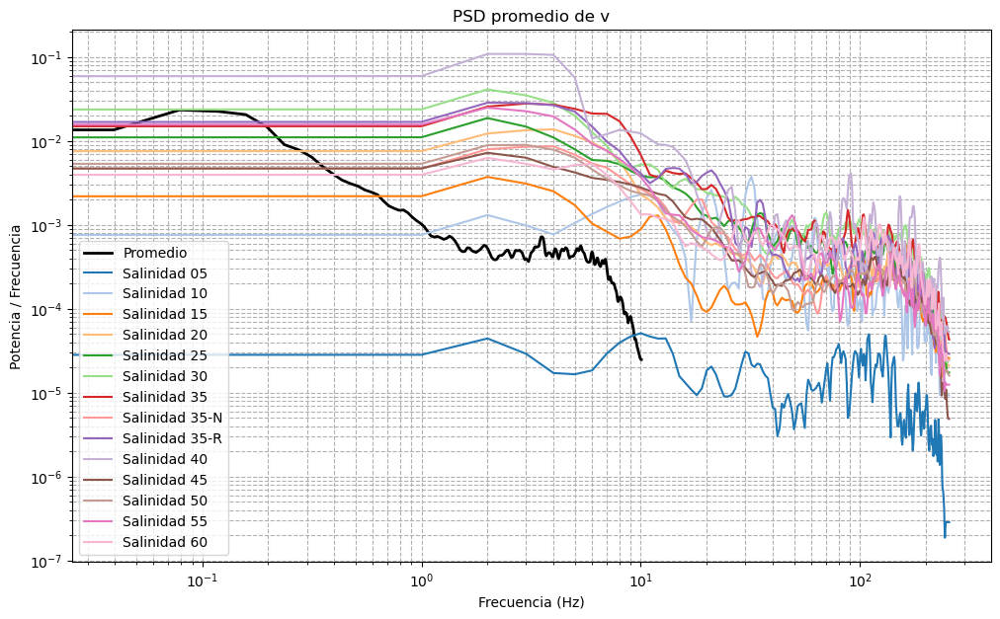


Características del PSD para análisis estadístico (ej. frecuencia dominante):


,id,salinidad,frecuencia_dominante,potencia_maxima
0,0,35-N,0.255326,0.004649
1,1,35-N,0.172283,0.032861
2,3,35-N,0.085207,0.001407
3,4,35-N,0.338282,0.004366
4,5,35-N,0.735117,0.029401


Calculando PSD para cada video...
PSD calculada para 578 videos.

Interpolando PSDs a una grilla común...


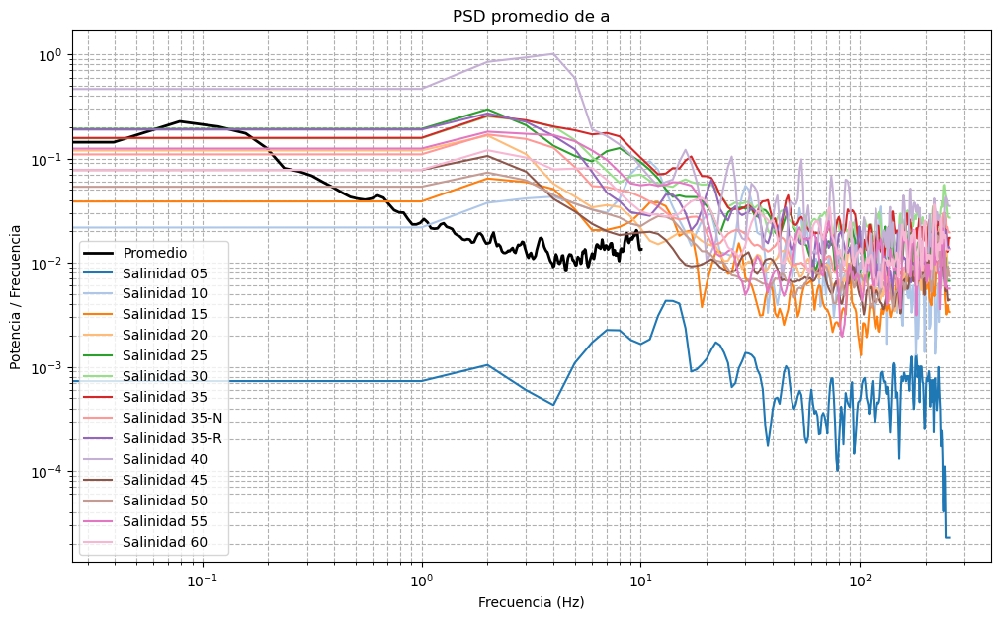


Características del PSD para análisis estadístico (ej. frecuencia dominante):


,id,salinidad,frecuencia_dominante,potencia_maxima
0,0,35-N,0.255326,0.004649
1,1,35-N,0.172283,0.032861
2,3,35-N,0.085207,0.001407
3,4,35-N,0.338282,0.004366
4,5,35-N,0.735117,0.029401


Calculando PSD para cada video...
PSD calculada para 867 videos.

Interpolando PSDs a una grilla común...


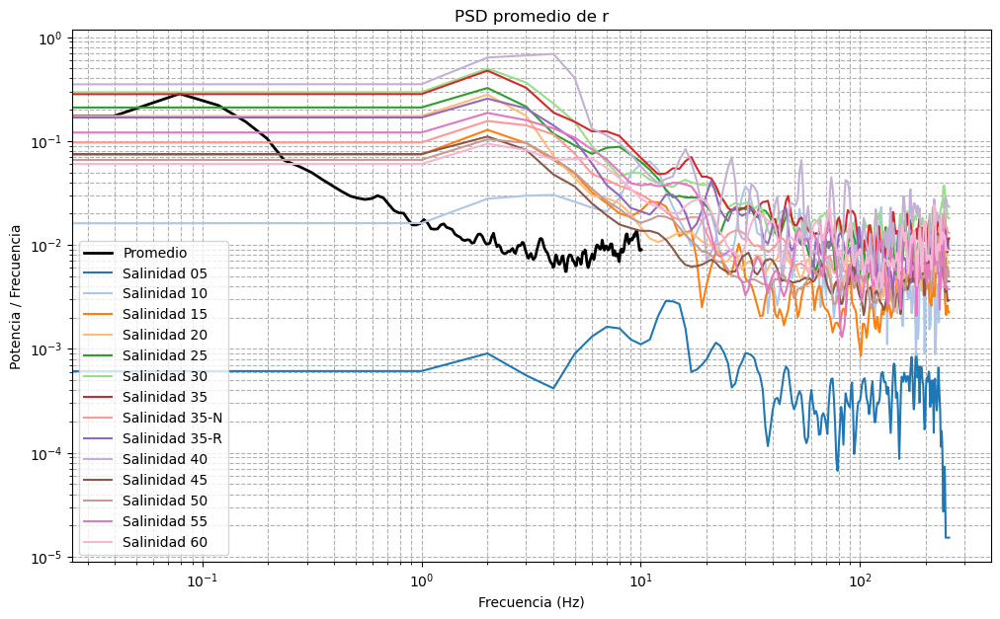


Características del PSD para análisis estadístico (ej. frecuencia dominante):


,id,salinidad,frecuencia_dominante,potencia_maxima
0,0,35-N,0.255326,0.004649
1,1,35-N,0.172283,0.032861
2,3,35-N,0.085207,0.001407
3,4,35-N,0.338282,0.004366
4,5,35-N,0.735117,0.029401


Calculando PSD para cada video...
PSD calculada para 1156 videos.

Interpolando PSDs a una grilla común...


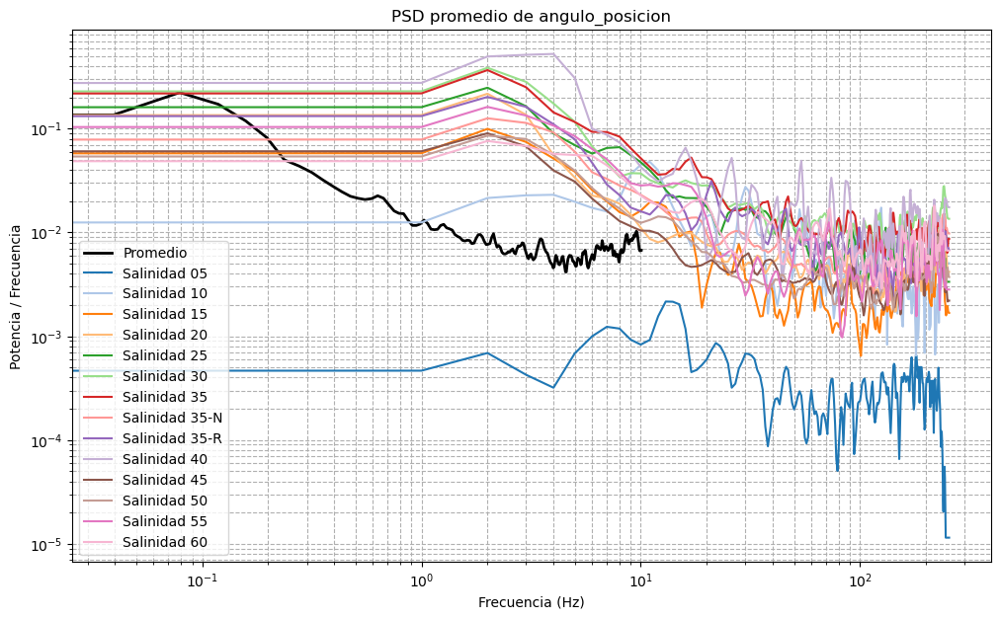


Características del PSD para análisis estadístico (ej. frecuencia dominante):


,id,salinidad,frecuencia_dominante,potencia_maxima
0,0,35-N,0.255326,0.004649
1,1,35-N,0.172283,0.032861
2,3,35-N,0.085207,0.001407
3,4,35-N,0.338282,0.004366
4,5,35-N,0.735117,0.029401


Calculando PSD para cada video...
PSD calculada para 1445 videos.

Interpolando PSDs a una grilla común...


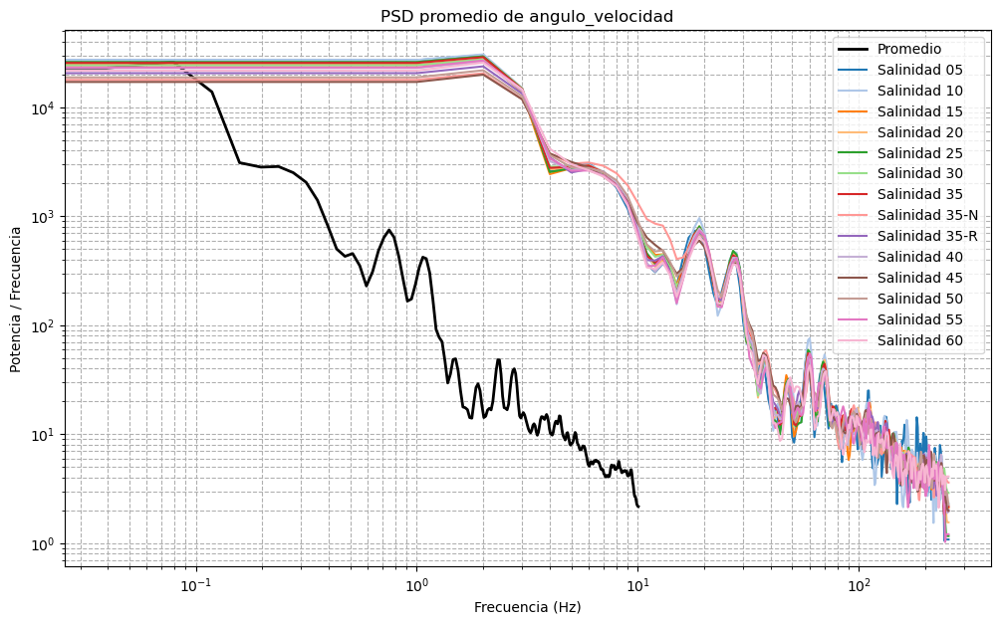


Características del PSD para análisis estadístico (ej. frecuencia dominante):


,id,salinidad,frecuencia_dominante,potencia_maxima
0,0,35-N,0.255326,0.004649
1,1,35-N,0.172283,0.032861
2,3,35-N,0.085207,0.001407
3,4,35-N,0.338282,0.004366
4,5,35-N,0.735117,0.029401


Calculando PSD para cada video...
PSD calculada para 1734 videos.

Interpolando PSDs a una grilla común...


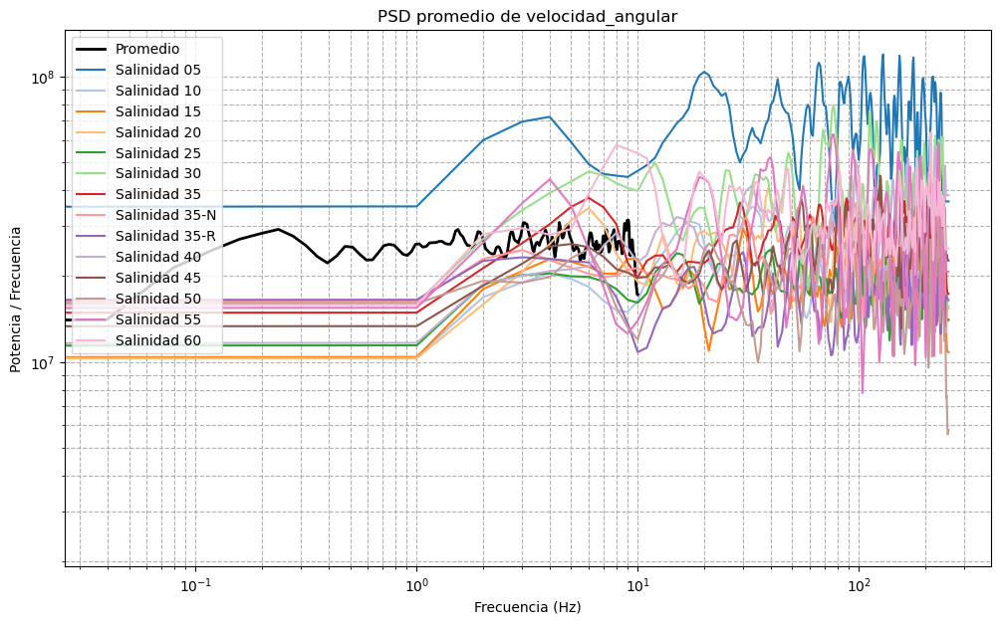


Características del PSD para análisis estadístico (ej. frecuencia dominante):


,id,salinidad,frecuencia_dominante,potencia_maxima
0,0,35-N,0.255326,0.004649
1,1,35-N,0.172283,0.032861
2,3,35-N,0.085207,0.001407
3,4,35-N,0.338282,0.004366
4,5,35-N,0.735117,0.029401


In [ ]:
from scipy.signal import welch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt # Asegúrate de tenerlo importado

variables = ['v', 'a', 'r', 'angulo_posicion', 'angulo_velocidad', 'velocidad_angular']

lista_psd_originales = [] # Guardaremos tuplas (frecuencias, psd)
todas_las_frecuencias_max = [] # Para definir una grilla común después

for variable in variables:
    print("Calculando PSD para cada video...")
    for id_video, grupo in df.groupby('id'):
        velocidad = grupo[variable].dropna()
        tiempo = grupo.loc[velocidad.index, 't'] # Asegúrate que 'tiempo' tenga los mismos índices que 'velocidad'
        
        if len(velocidad) < 10: # Necesitamos suficientes puntos para una PSD razonable
            print(f"Video {id_video} tiene muy pocos puntos ({len(velocidad)}) para PSD, omitiendo.")
            continue
            
        # Calculamos la frecuencia de muestreo promedio para este video
        # Es importante que 'tiempo' y 'velocidad' estén alineados
        intervalos_tiempo = np.diff(tiempo)
        if np.any(intervalos_tiempo <= 0): # Chequeo por tiempos no crecientes o duplicados
            print(f"Video {id_video} tiene intervalos de tiempo no válidos, omitiendo PSD.")
            continue
        
        fs_video = 1 / np.mean(intervalos_tiempo)
        
        # Calculamos la PSD usando el método de Welch
        # nperseg define la resolución. Un valor fijo puede ser mejor si fs es similar.
        # Si fs varía mucho, la interpolación es aún más crucial.
        frecuencias_video, psd_video = welch(velocidad, fs=fs_video, nperseg=min(len(velocidad), 256))
        
        lista_psd_originales.append({'id': id_video, 
                                    'frecuencias': frecuencias_video, 
                                    'psd': psd_video,
                                    'salinidad': grupo['salinidad'].iloc[0] # Guardamos la salinidad
                                    })
        if len(frecuencias_video) > 0:
            todas_las_frecuencias_max.append(frecuencias_video[-1])

    print(f"PSD calculada para {len(lista_psd_originales)} videos.")

    # --- Interpolación a una grilla común ---
    if lista_psd_originales:
        # Definimos la grilla de frecuencias común
        # Usaremos hasta la frecuencia máxima encontrada, con 256 puntos (puedes ajustar)
        f_max_comun = max(todas_las_frecuencias_max) if todas_las_frecuencias_max else 10 # Default si no hay frecuencias
        grid_frecuencias_comun = np.linspace(0, f_max_comun, 256) # 256 puntos en la grilla

        lista_psd_interpoladas = []
        print("\nInterpolando PSDs a una grilla común...")
        for item_psd in lista_psd_originales:
            # np.interp necesita que las frecuencias originales estén ordenadas
            # y no contengan duplicados, welch ya debería devolverlas así.
            psd_interpolada = np.interp(grid_frecuencias_comun, item_psd['frecuencias'], item_psd['psd'])
            lista_psd_interpoladas.append(psd_interpolada)

        # Ahora promediamos las PSD interpoladas
        psd_media_total = np.mean(lista_psd_interpoladas, axis=0)

        # Graficamos la PSD promedio total
        plt.figure(figsize=(12, 7))
        plt.loglog(grid_frecuencias_comun, psd_media_total, color = 'black', linewidth = 2, label="Promedio")
        plt.title(f'PSD promedio de {variable}')
        plt.xlabel('Frecuencia (Hz)')
        plt.ylabel('Potencia / Frecuencia')
        
        # --- Opcional: Graficar PSD promedio POR GRUPO DE SALINIDAD ---
        # Necesitarás agrupar 'lista_psd_originales' por salinidad primero
        # y luego interpolar y promediar para cada grupo.
        
        df_psd_temp = pd.DataFrame(lista_psd_originales)
        
        # --- Graficar PSD promedio POR GRUPO DE SALINIDAD con colores distintos ---
        df_psd_temp = pd.DataFrame(lista_psd_originales)

        salinidades_unicas = sorted(df_psd_temp['salinidad'].unique())
        # Usa tab20 para más de 10 colores, o usa viridis/plasma/etc. para gradientes
        cmap = plt.get_cmap('tab20')  # Puedes usar 'nipy_spectral' o 'tab20b' si prefieres
        color_dict = {sal: cmap(i % 20) for i, sal in enumerate(salinidades_unicas)}

        for salinidad_nivel, datos_grupo in df_psd_temp.groupby('salinidad'):
            psds_grupo_interpoladas = []
            for _, fila in datos_grupo.iterrows():
                psd_interp_grupo = np.interp(grid_frecuencias_comun, fila['frecuencias'], fila['psd'])
                psds_grupo_interpoladas.append(psd_interp_grupo)
            
            if psds_grupo_interpoladas:
                psd_media_grupo = np.mean(psds_grupo_interpoladas, axis=0)
                plt.plot(psd_media_grupo, 
                        label=f"Salinidad {salinidad_nivel}",
                        color=color_dict[salinidad_nivel])  # Color distintivo

        plt.legend()
        plt.grid(True, which="both", linestyle='--')
        plt.show()
        
        # --- Para el análisis estadístico de la frecuencia dominante ---
        # Ahora puedes recalcular las características del PSD usando la grilla común si es necesario,
        # o usar las originales y comparar las frecuencias dominantes como lo hicimos antes.
        # Si comparas las frecuencias dominantes directamente de las PSD originales,
        # no necesitas esta interpolación para ESE análisis específico, solo para el promedio.

        lista_resultados_dominantes = []
        for item_psd in lista_psd_originales:
            if len(item_psd['psd']) > 0:
                indice_max_potencia = np.argmax(item_psd['psd'])
                frec_dominante = item_psd['frecuencias'][indice_max_potencia]
                max_potencia = item_psd['psd'][indice_max_potencia]
                lista_resultados_dominantes.append({
                    'id': item_psd['id'],
                    'salinidad': item_psd['salinidad'],
                    'frecuencia_dominante': frec_dominante,
                    'potencia_maxima': max_potencia
                })
        
        df_psd_caracteristicas = pd.DataFrame(lista_resultados_dominantes)
        print("\nCaracterísticas del PSD para análisis estadístico (ej. frecuencia dominante):")
        display(df_psd_caracteristicas.head())

    else:
        print("No se calcularon PSDs, no se puede promediar o graficar.")

________________________

In [ ]:
import pathlib

output_dir = pathlib.Path('..') / '..' / 'resultados' / 'unfinished' / 'psd'
output_dir.mkdir(parents=True, exist_ok=True)

In [ ]:
print(df.columns)

Index(['id', 't', 'x', 'y', 'vx', 'vy', 'v', 'ax', 'ay', 'a', 'id_ubicacion',
       'especie', 'tratamiento', 'salinidad', 'nombre_archivo',
       'estadio_larval', 'obs', 'video_analizado', 'larva_unica',
       'duracion_video', 'angulo_posicion', 'angulo_velocidad',
       'velocidad_angular', 'x_centrada', 'y_centrada', 'r'],
      dtype='object')


Calculando PSD para cada trayectoria y variable...
PSD calculada para 1734 combinaciones de video/variable.

Usando grilla de frecuencias común global hasta 10.06 Hz


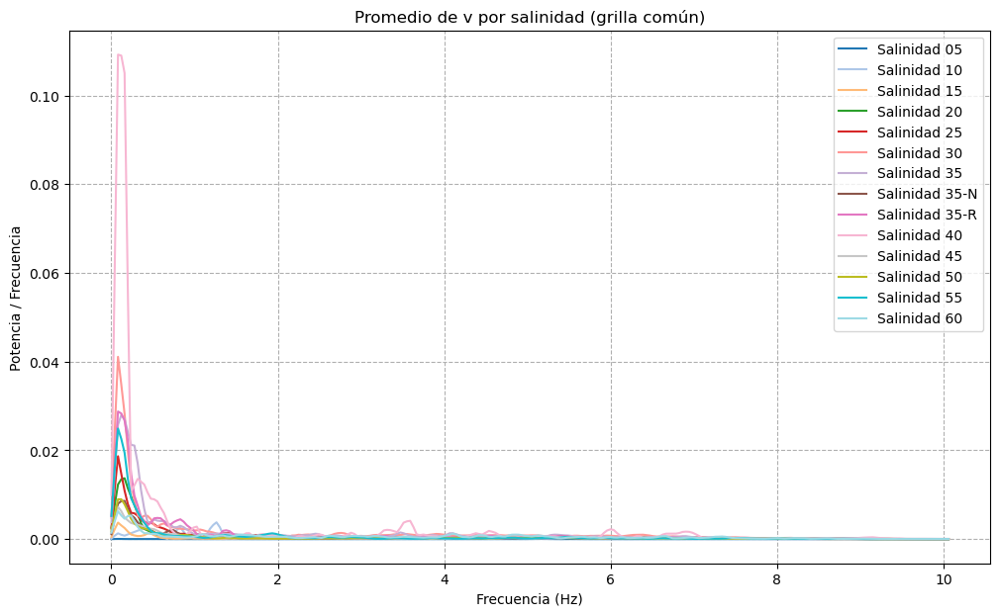


Generando gráficos PSD individuales + media para v por salinidad (usando grilla global)...


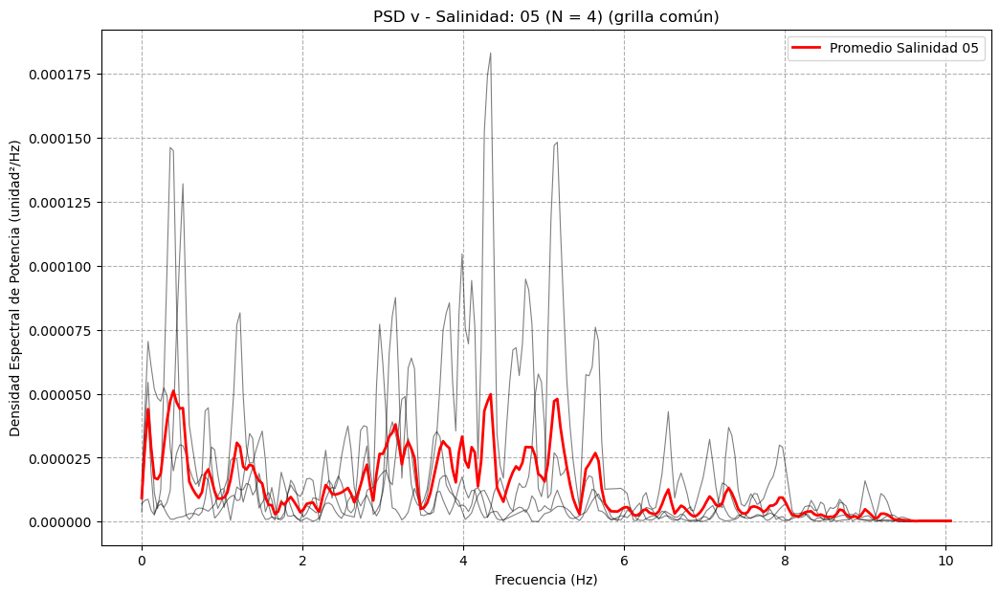

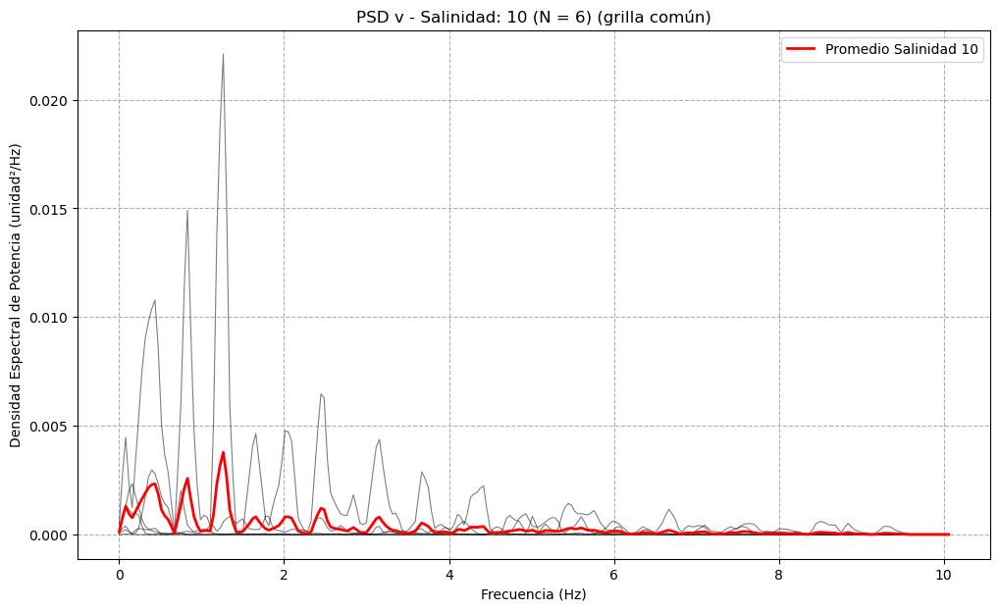

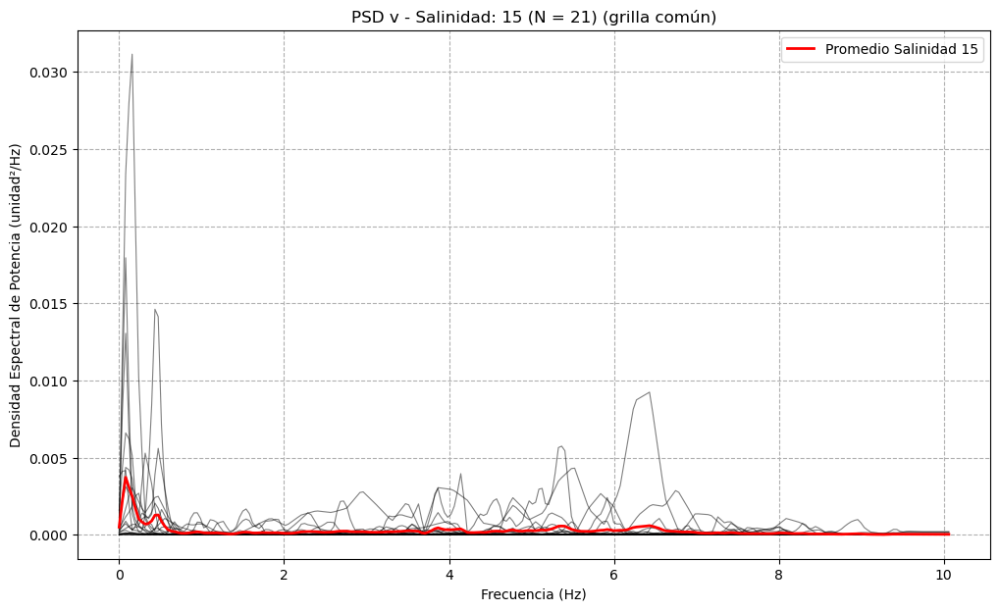

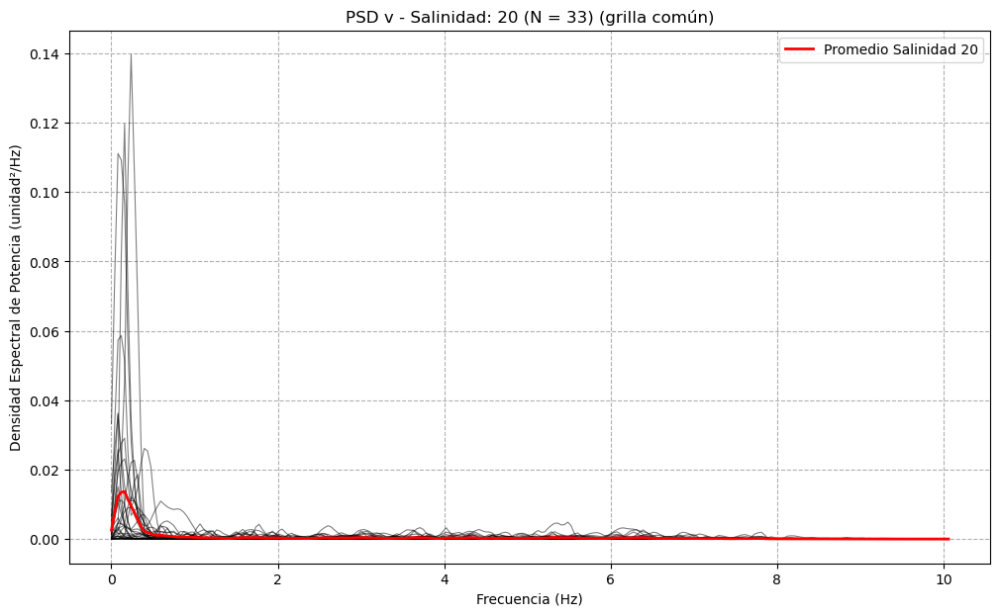

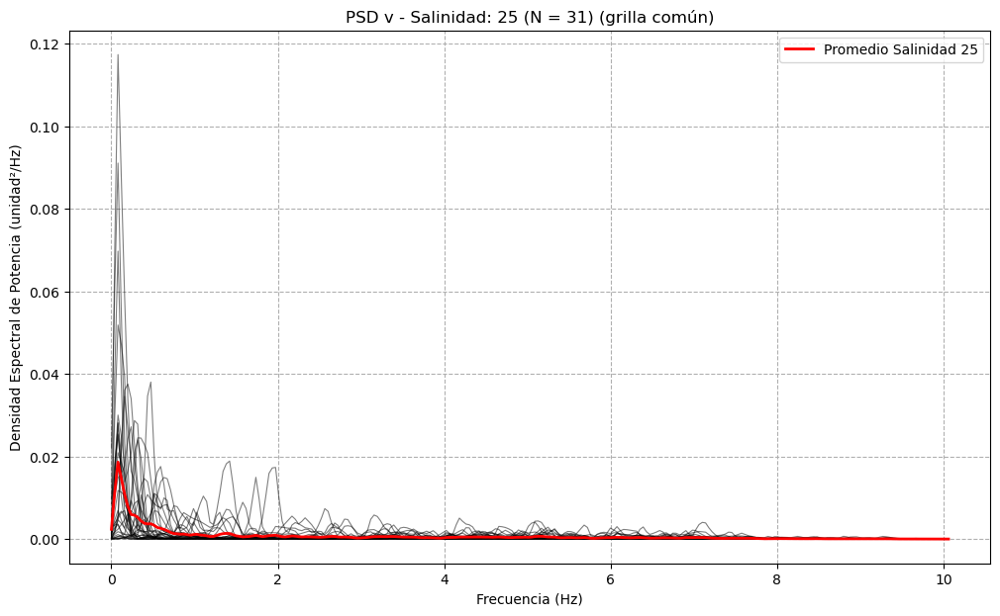

...

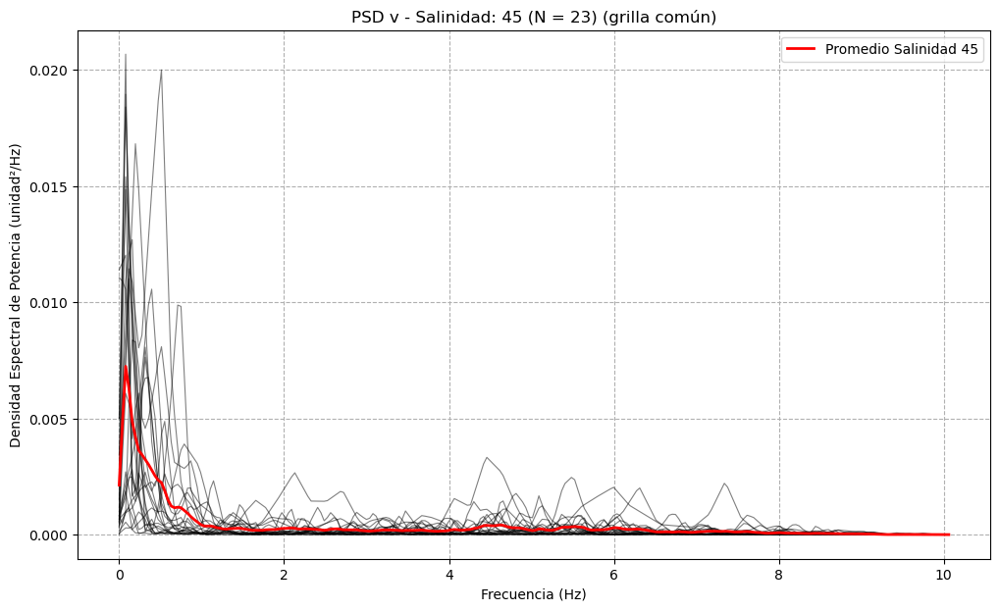

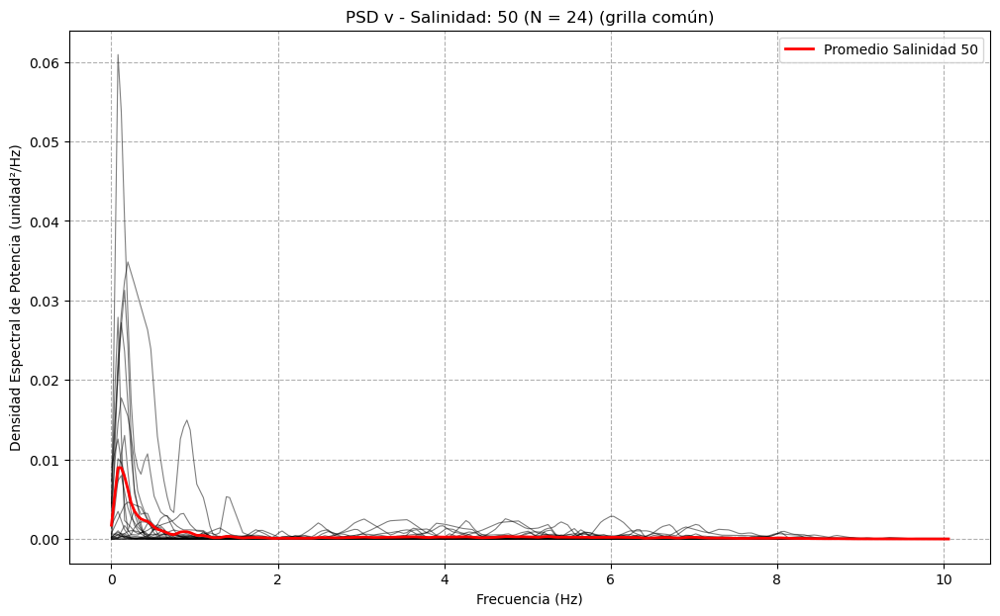

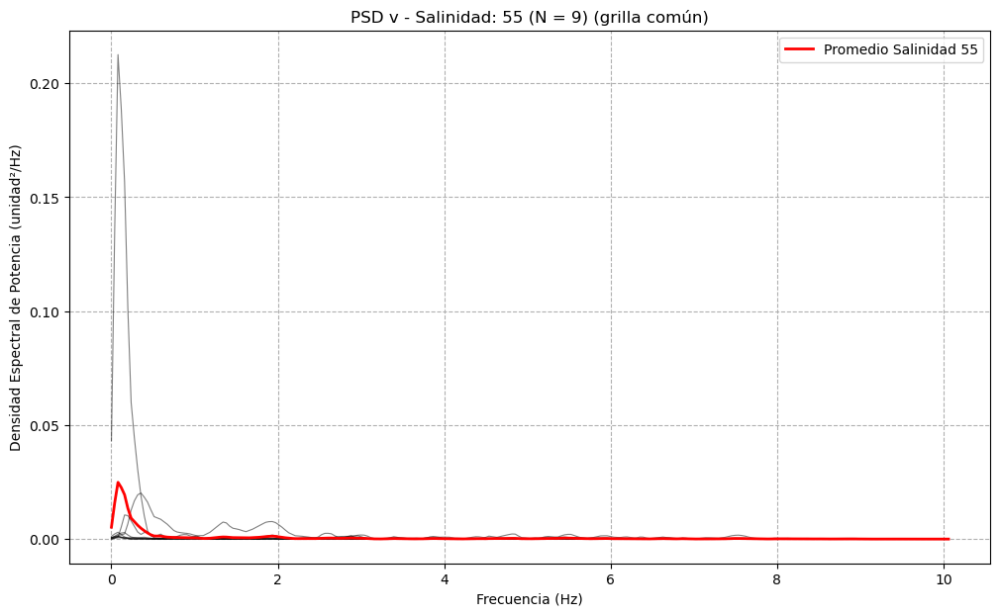

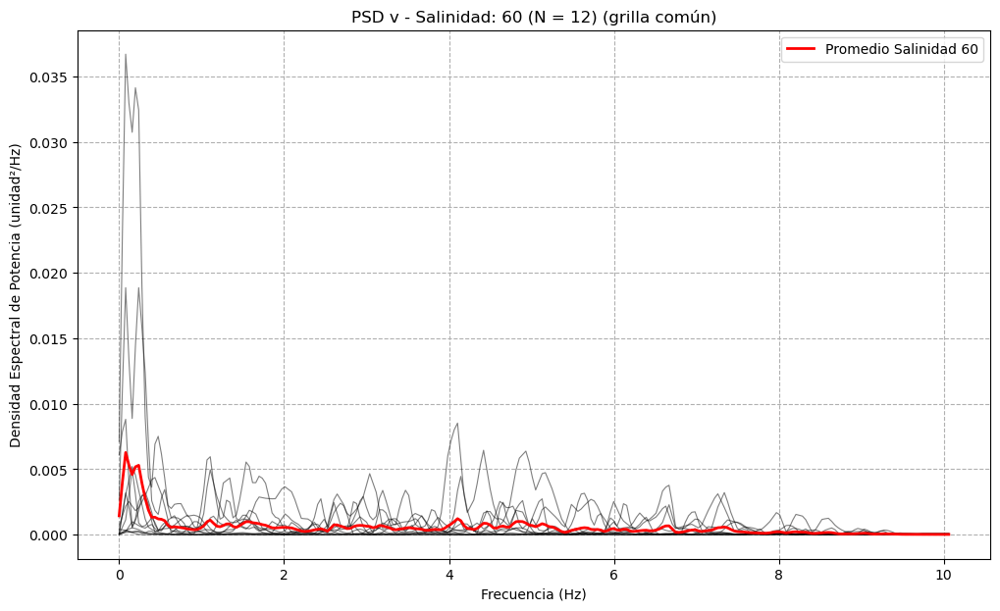

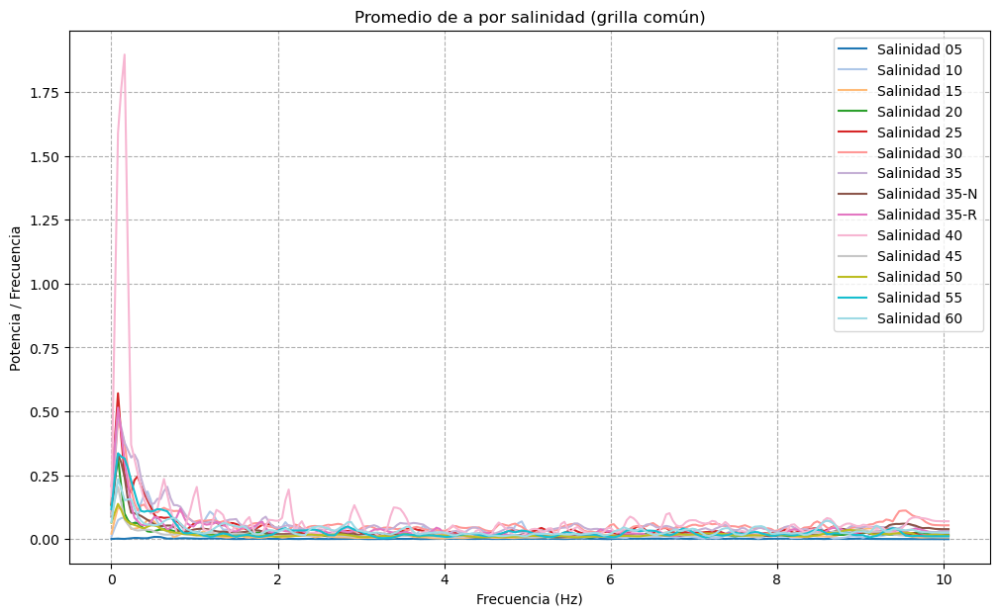


Generando gráficos PSD individuales + media para a por salinidad (usando grilla global)...


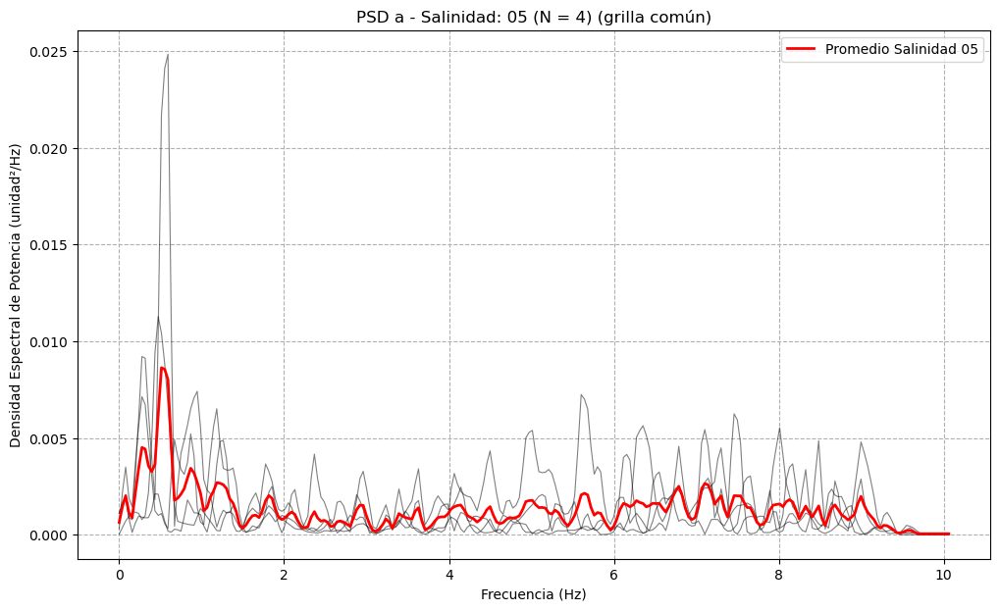

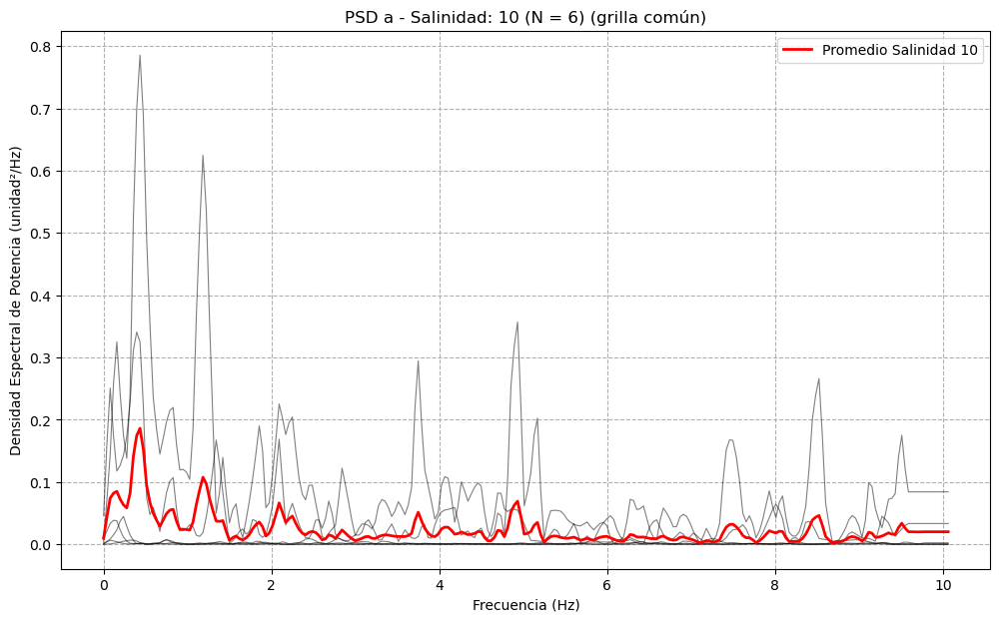

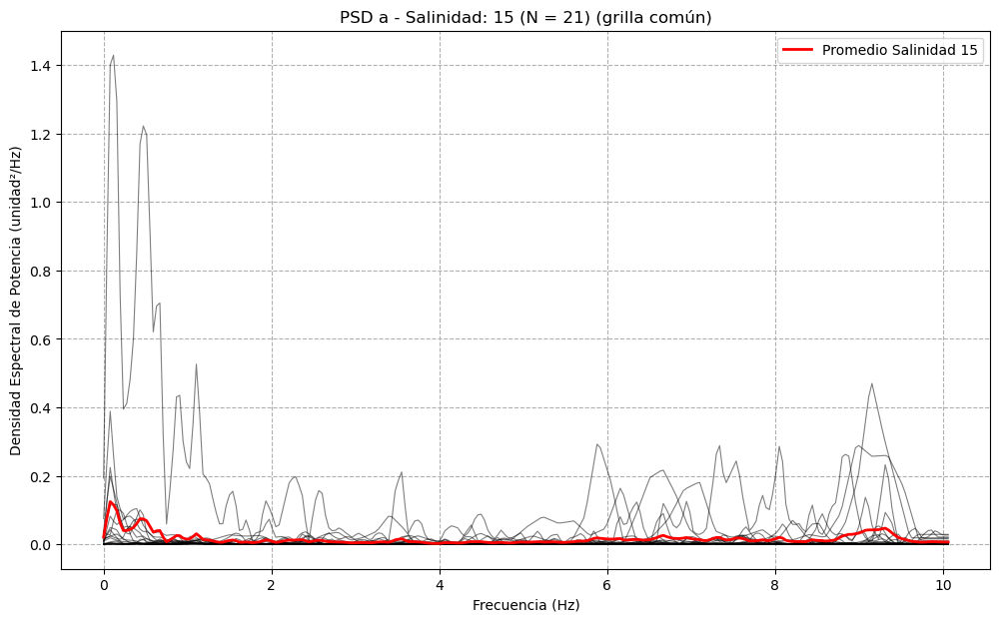

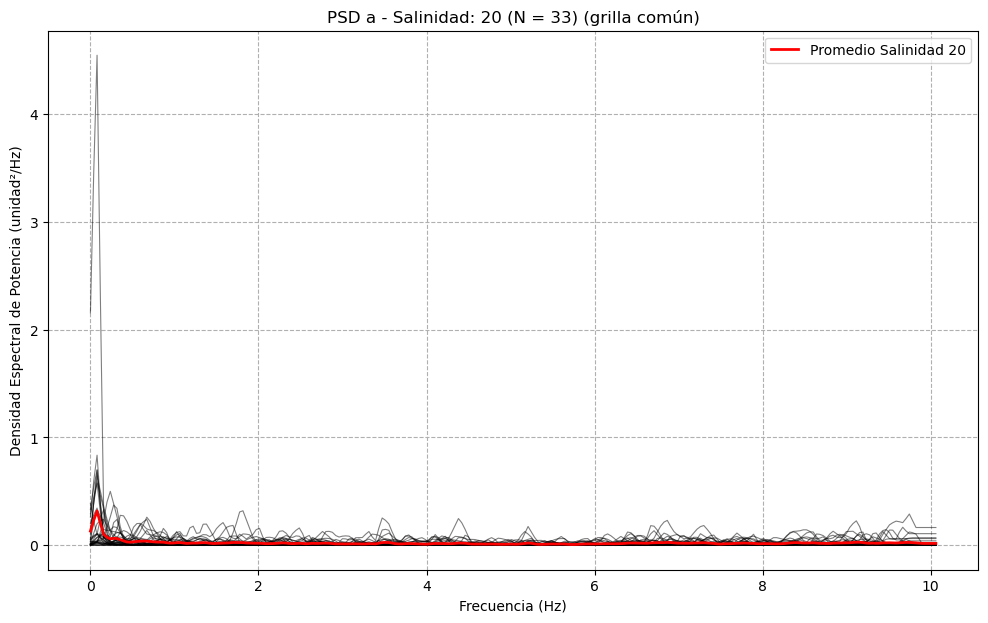

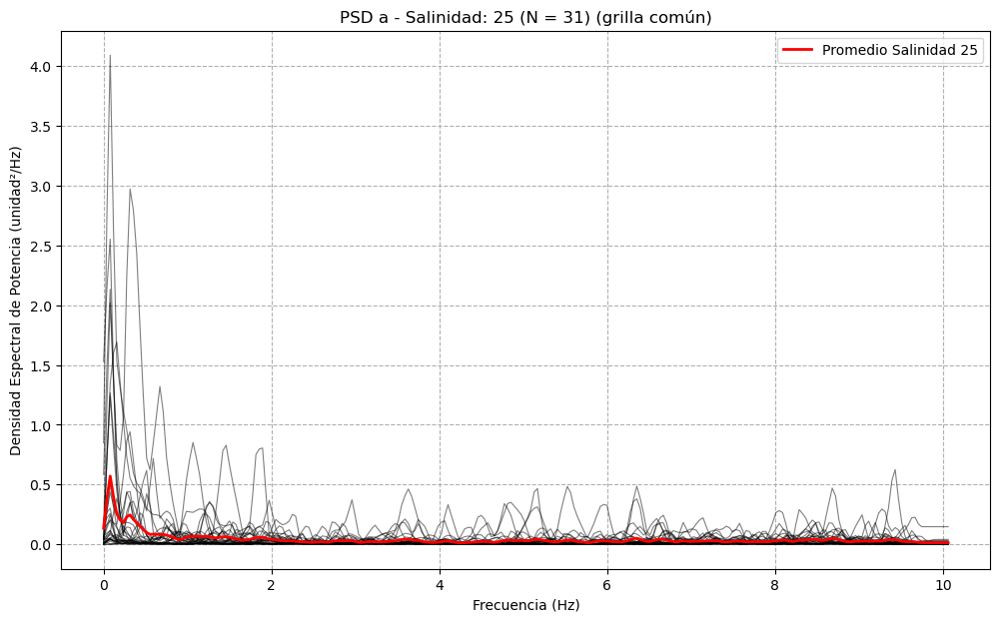

...

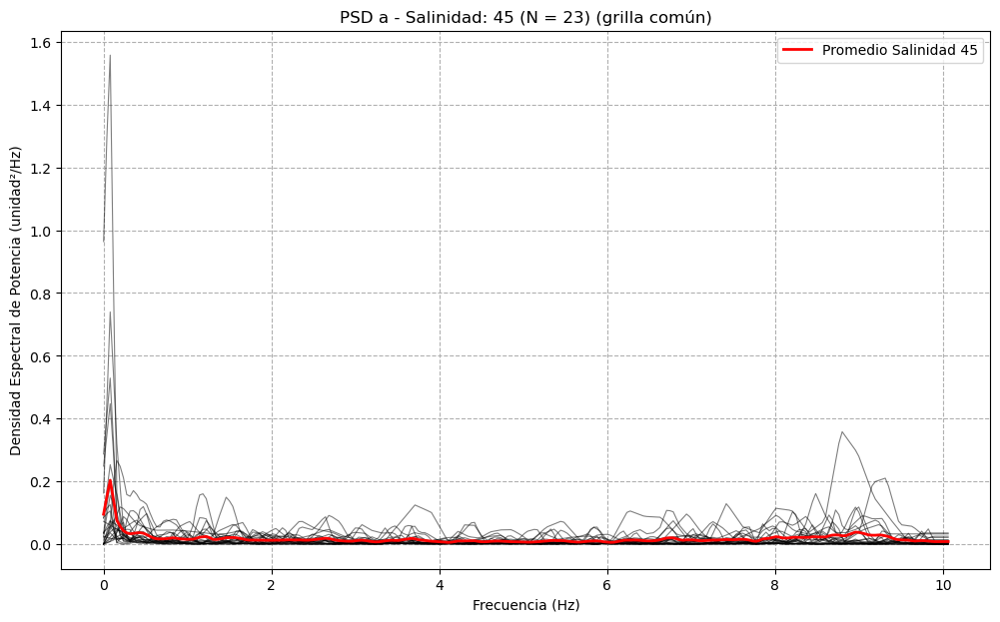

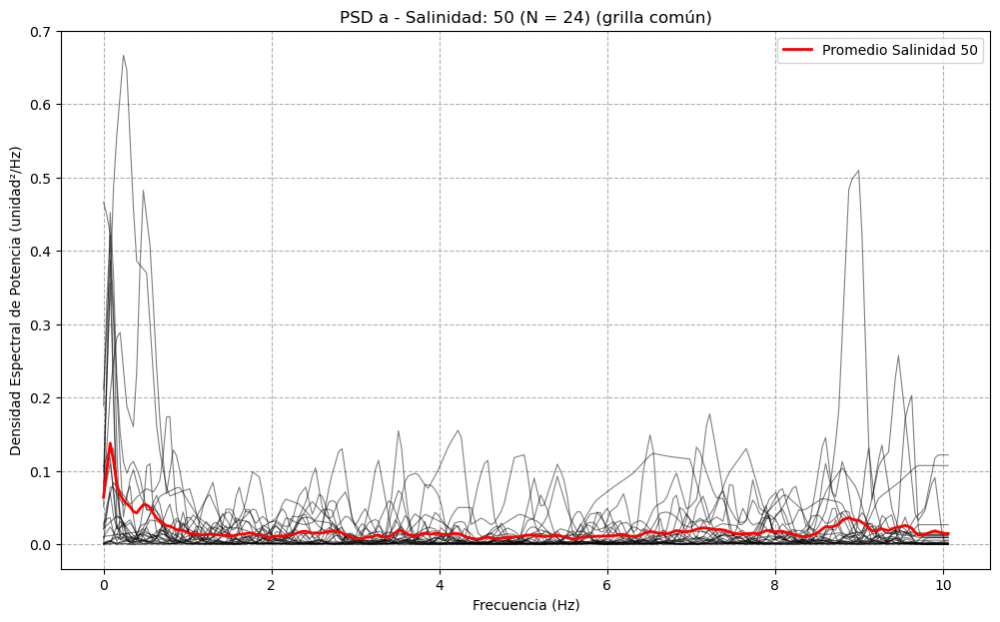

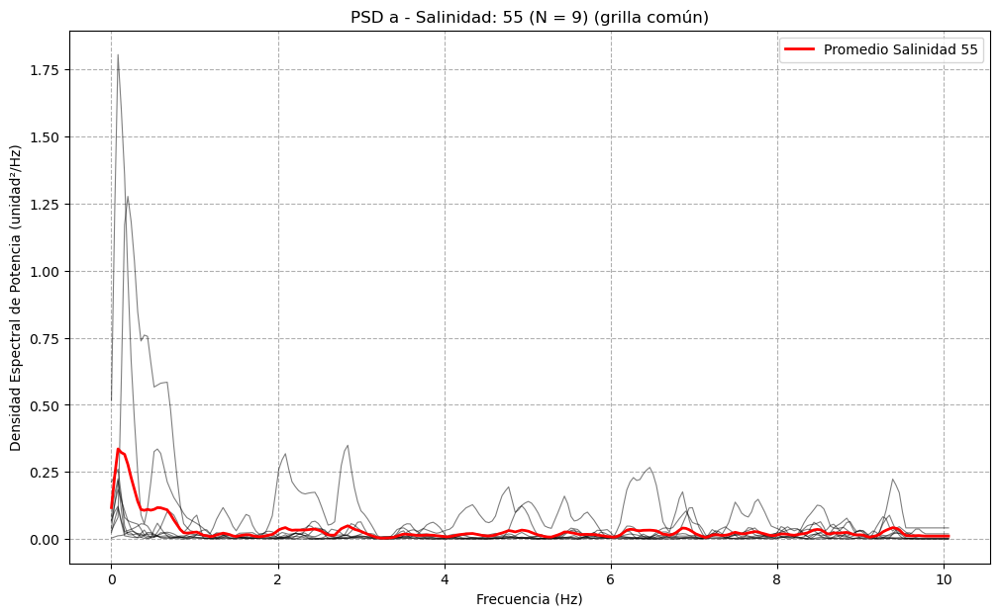

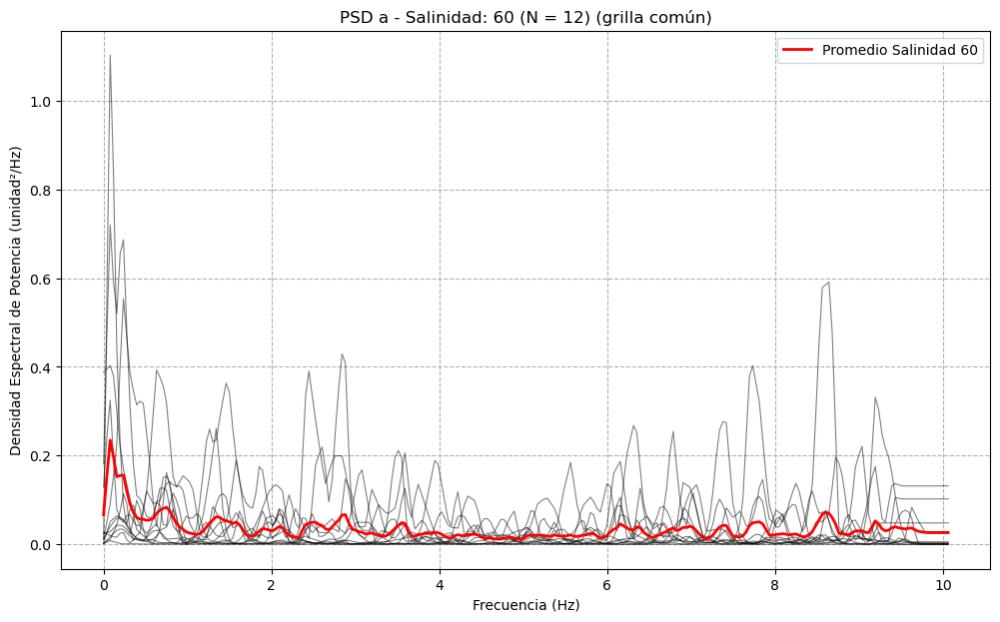

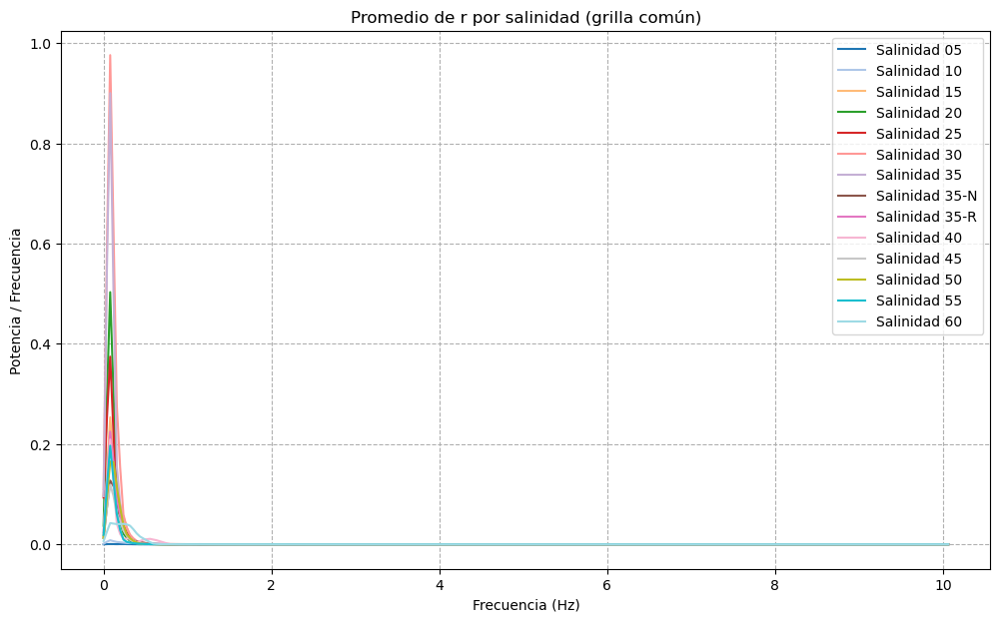


Generando gráficos PSD individuales + media para r por salinidad (usando grilla global)...


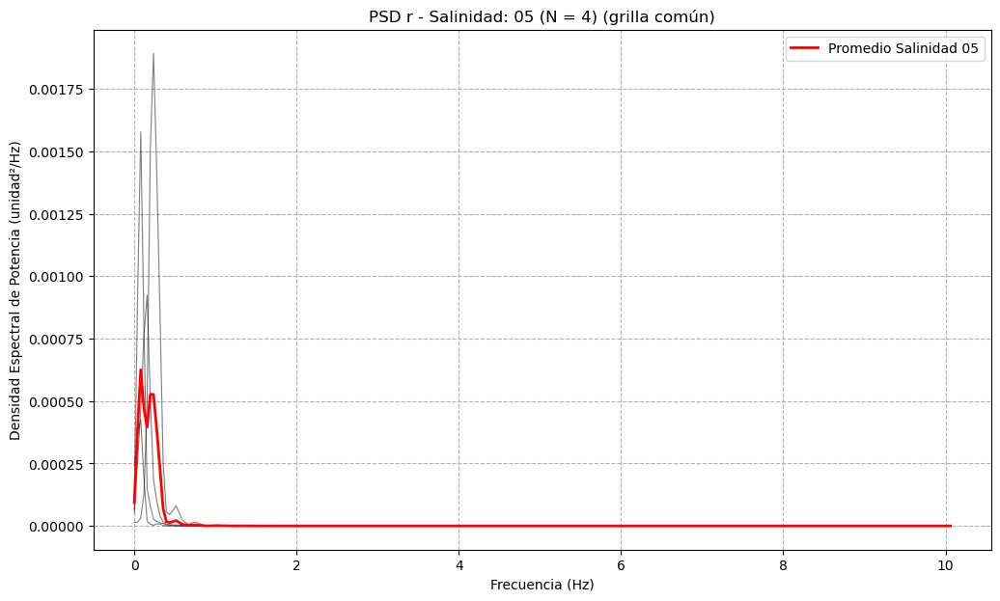

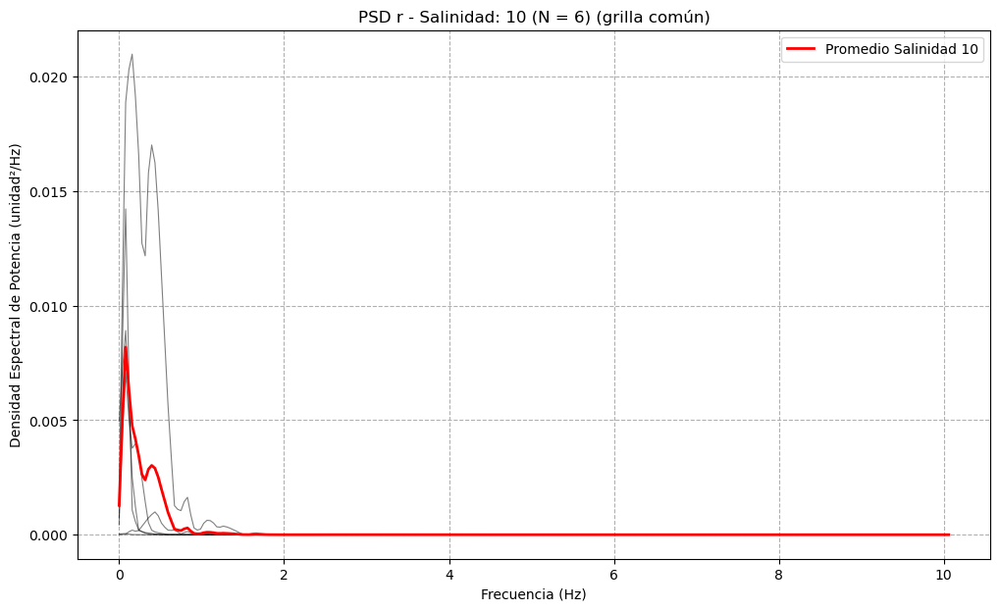

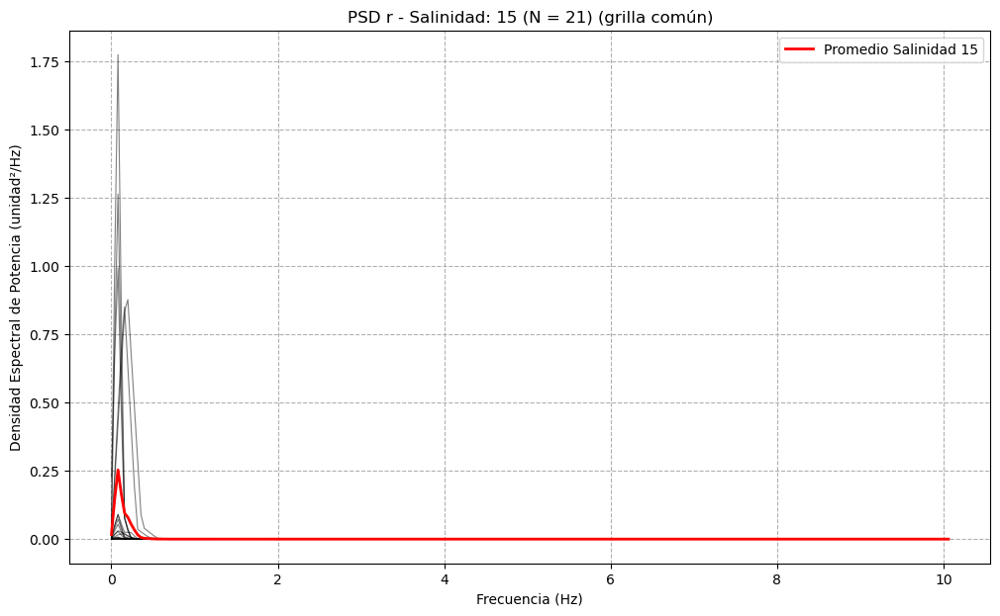

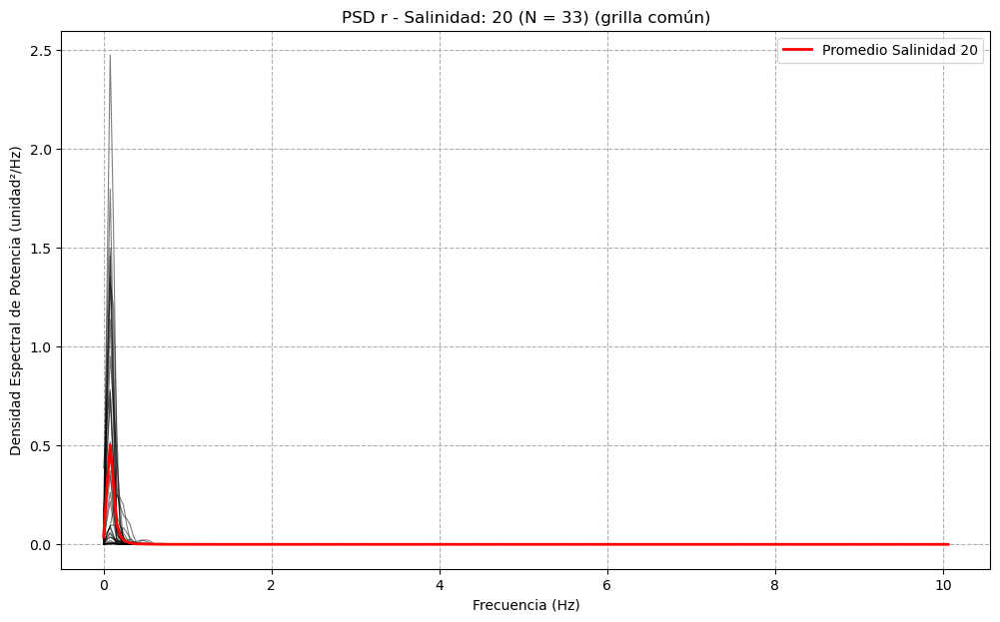

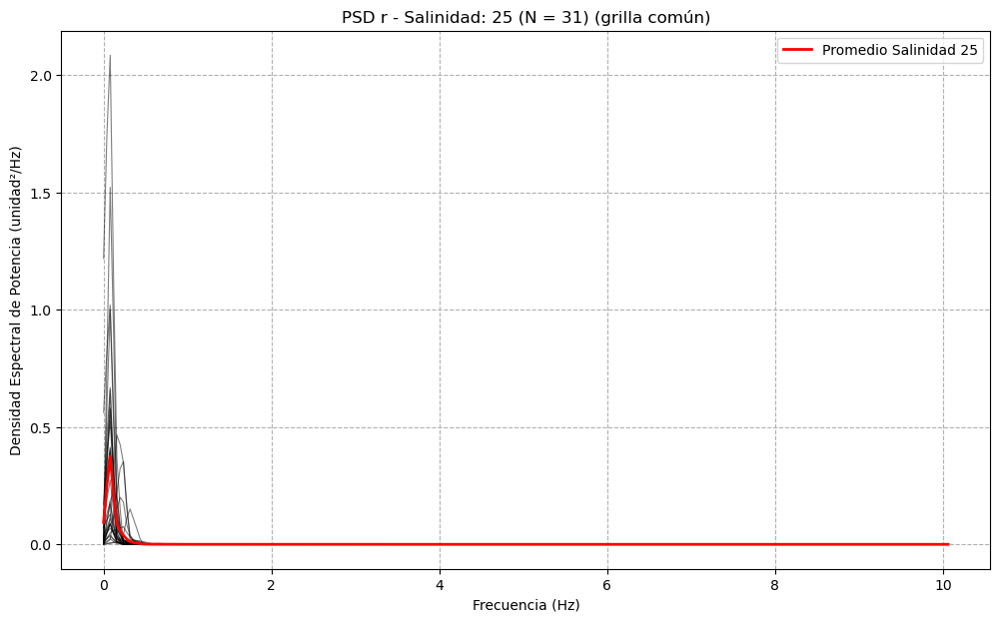

...

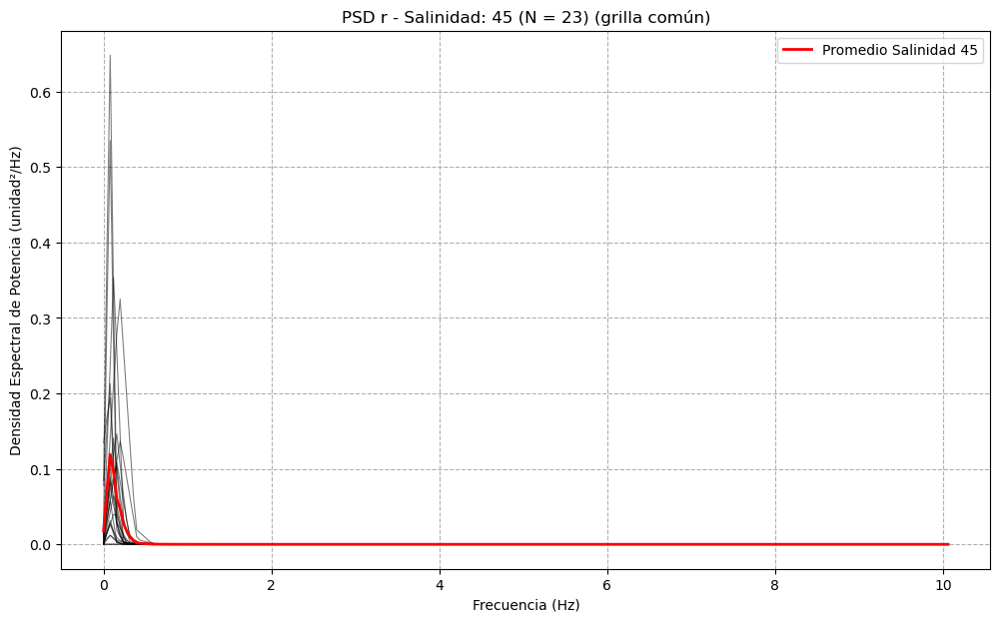

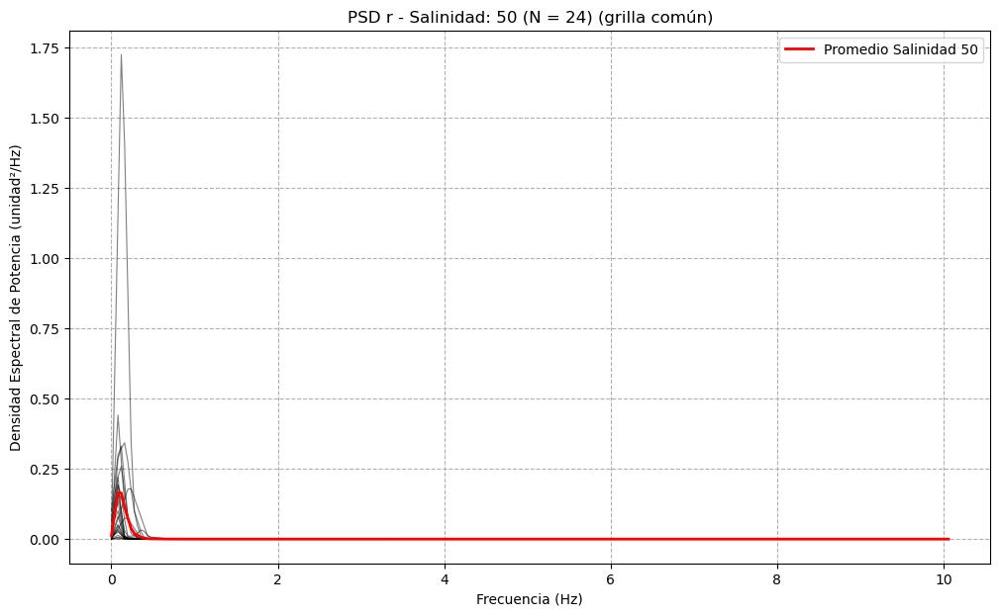

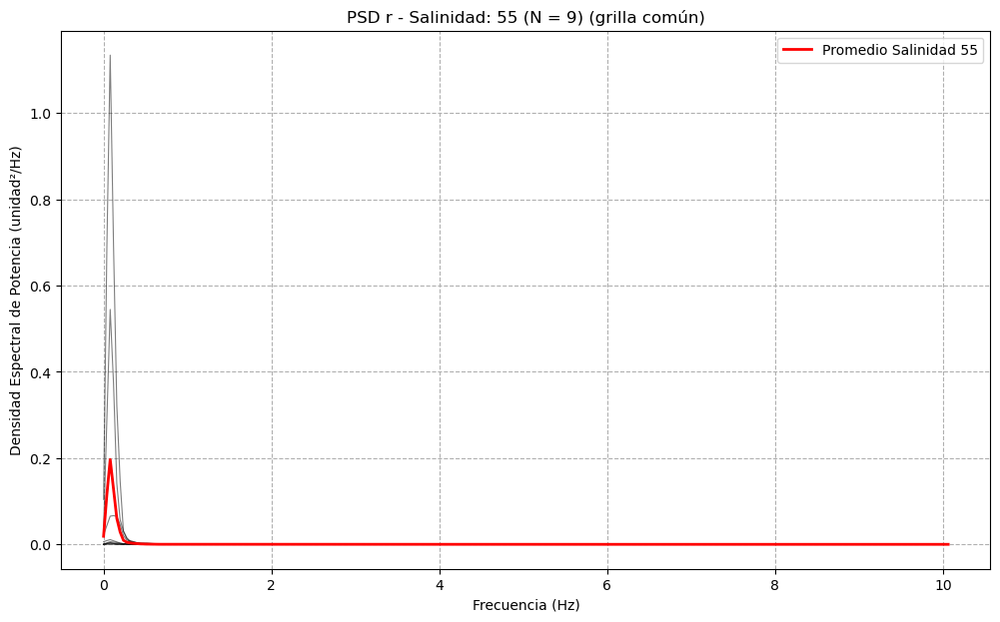

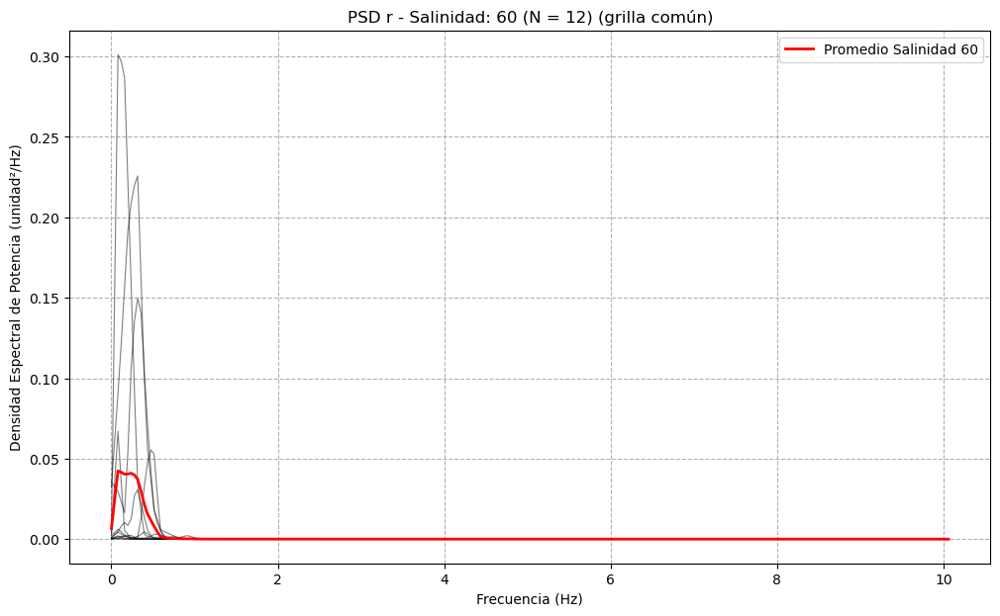

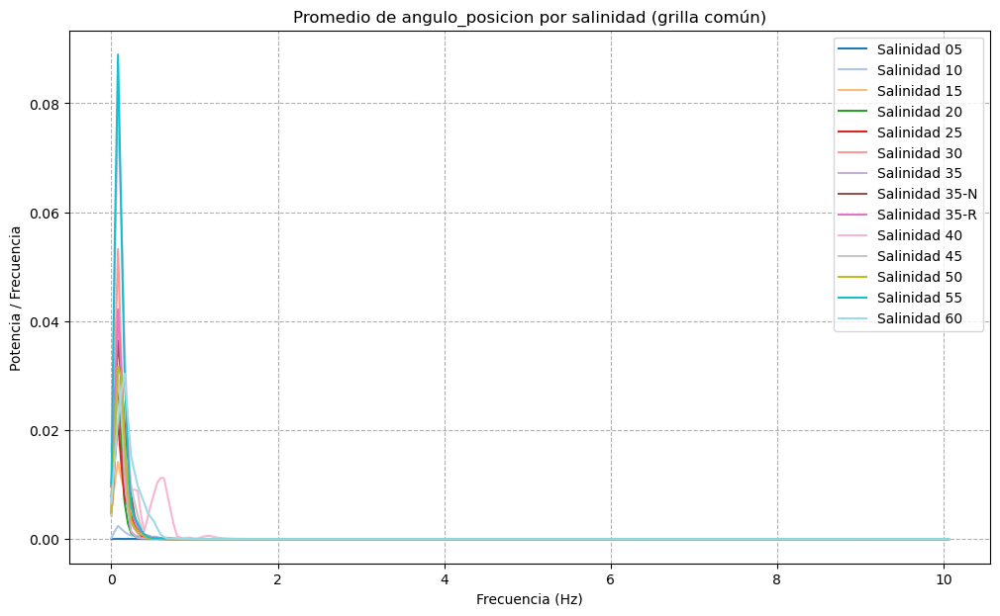


Generando gráficos PSD individuales + media para angulo_posicion por salinidad (usando grilla global)...


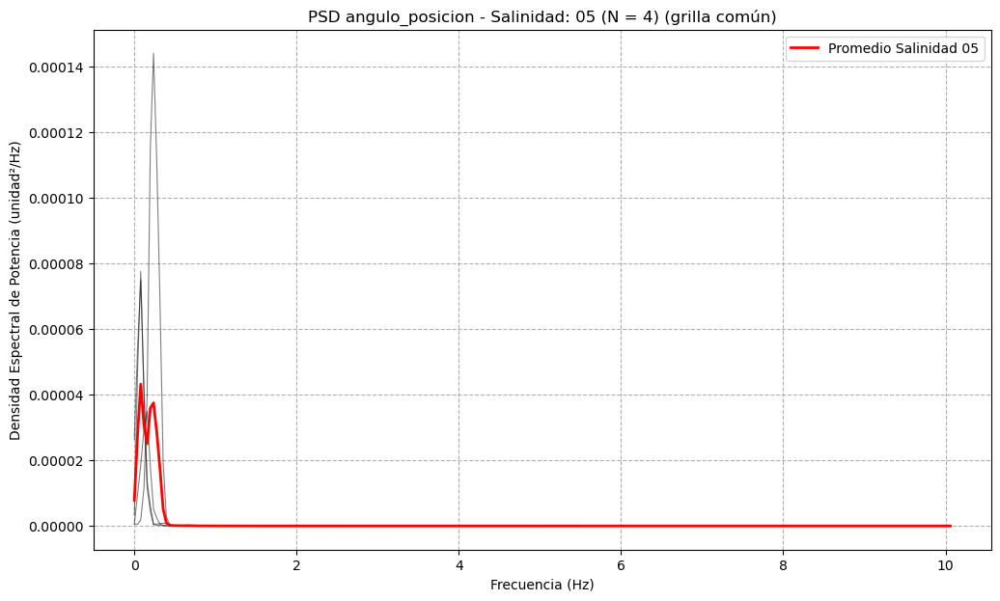

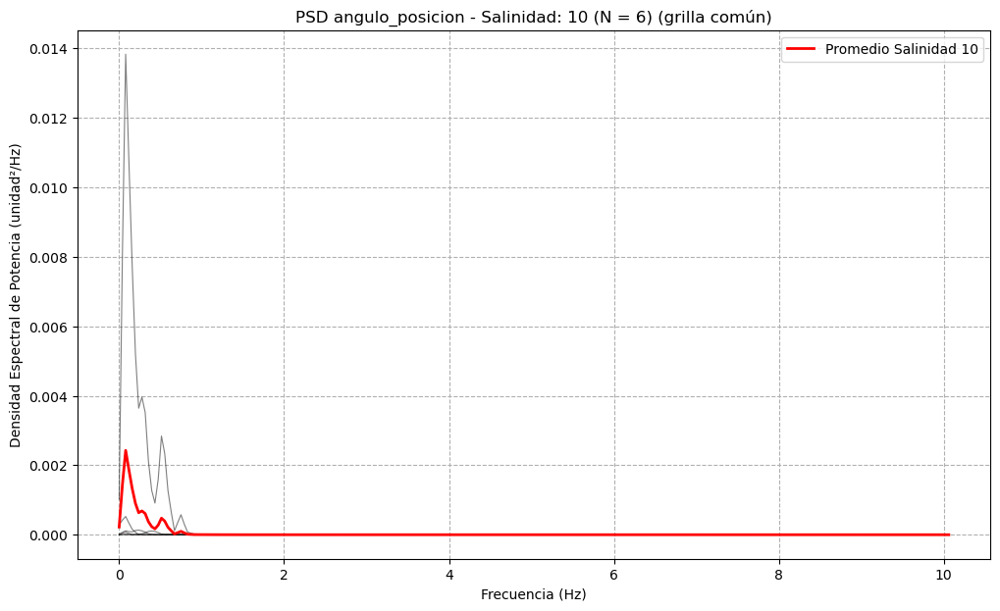

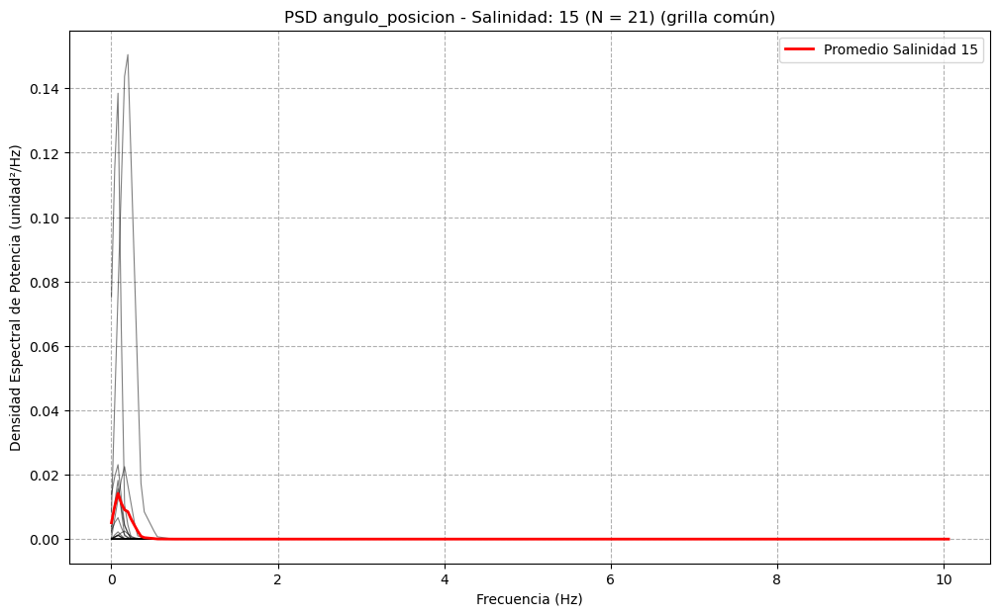

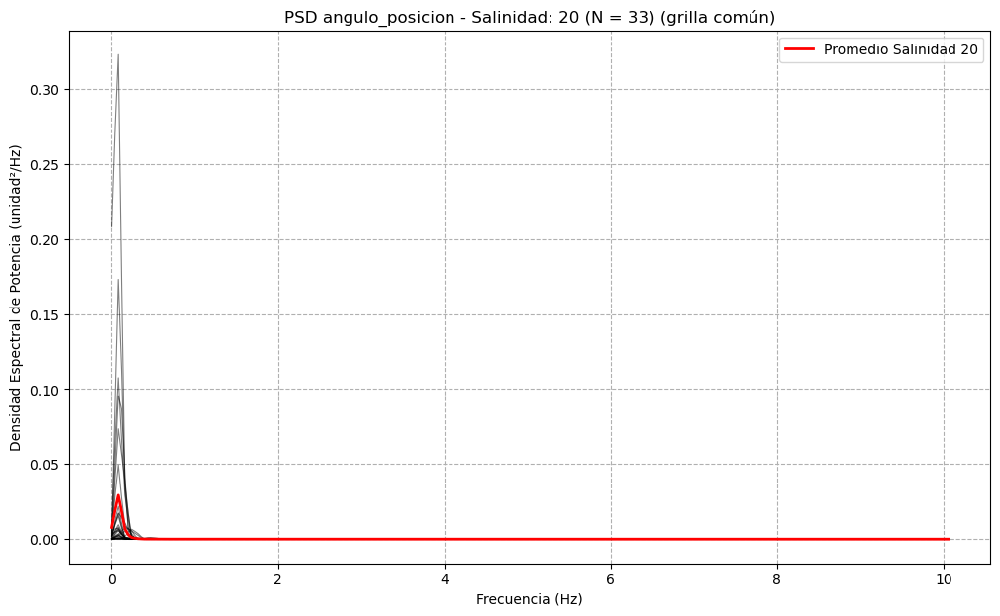

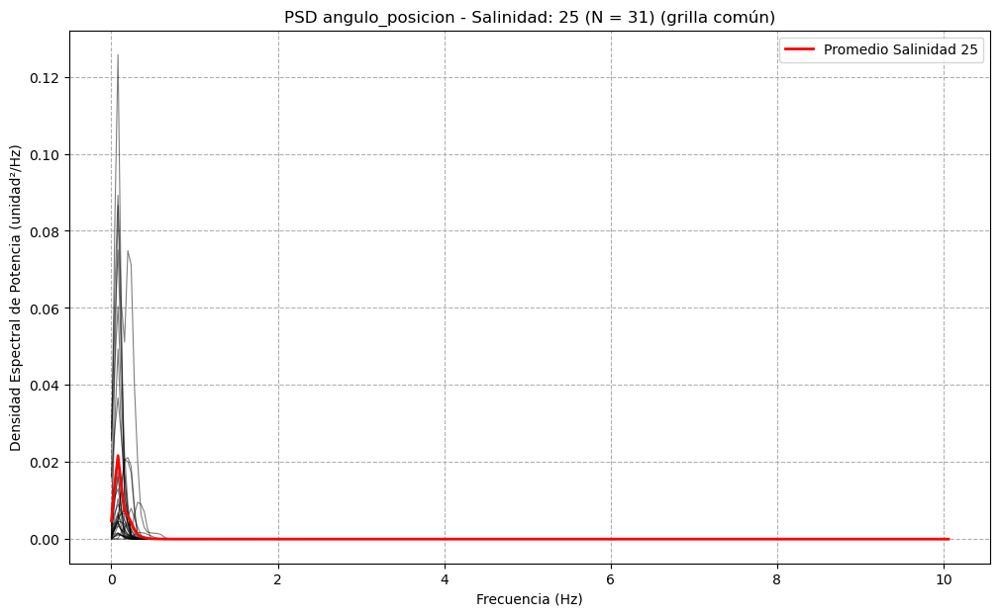

...

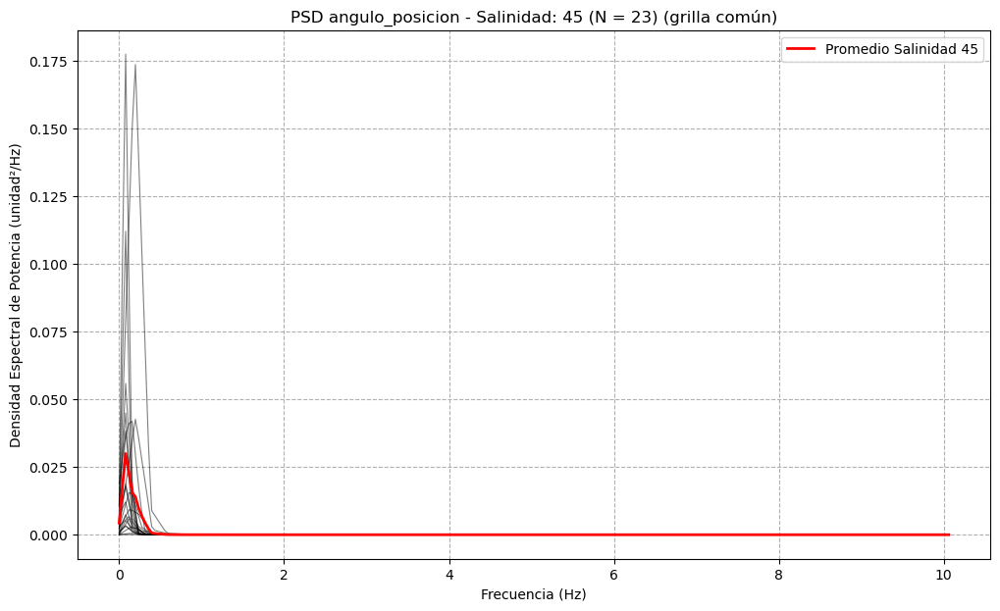

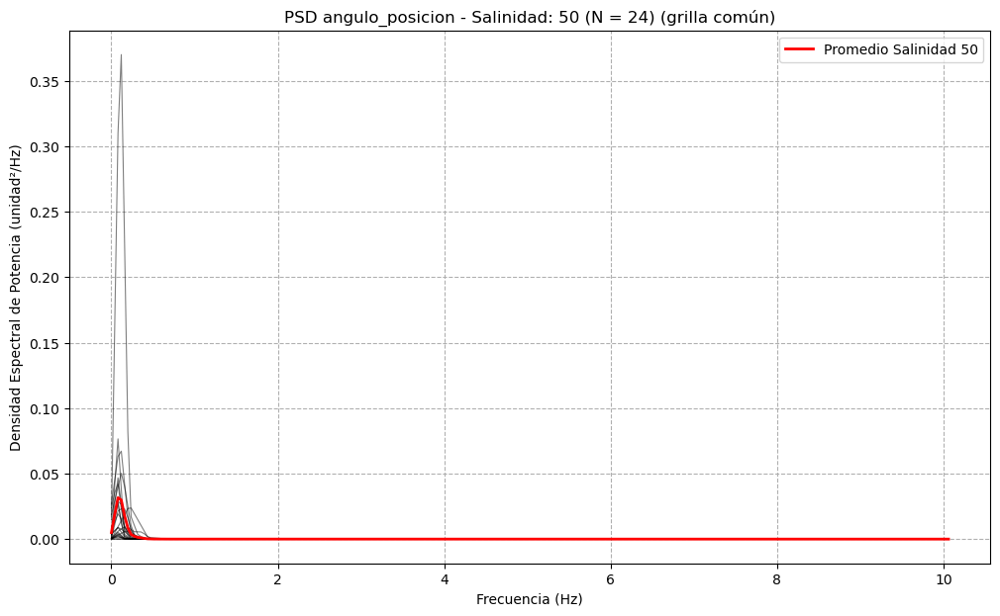

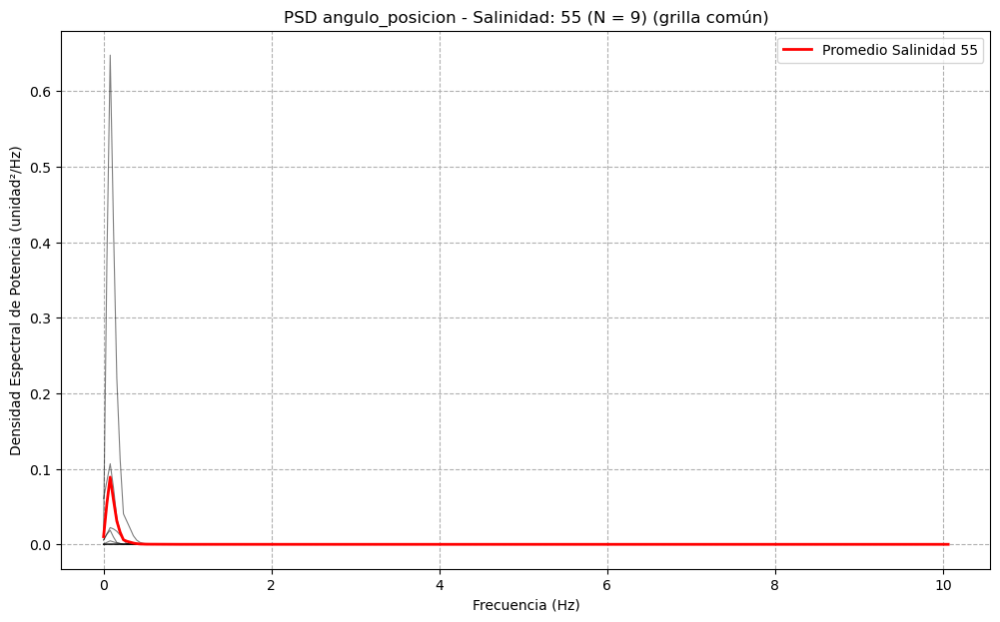

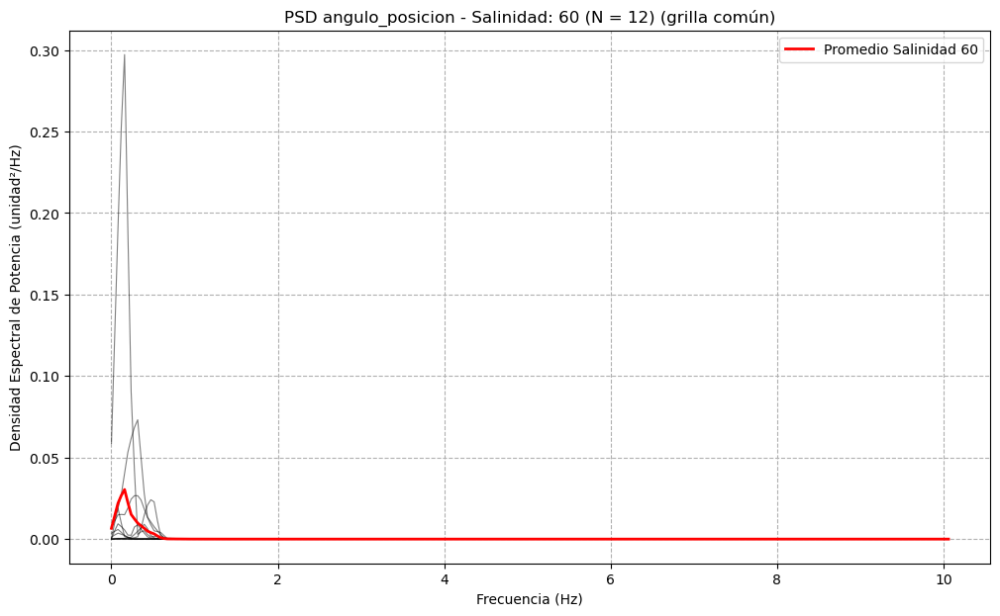

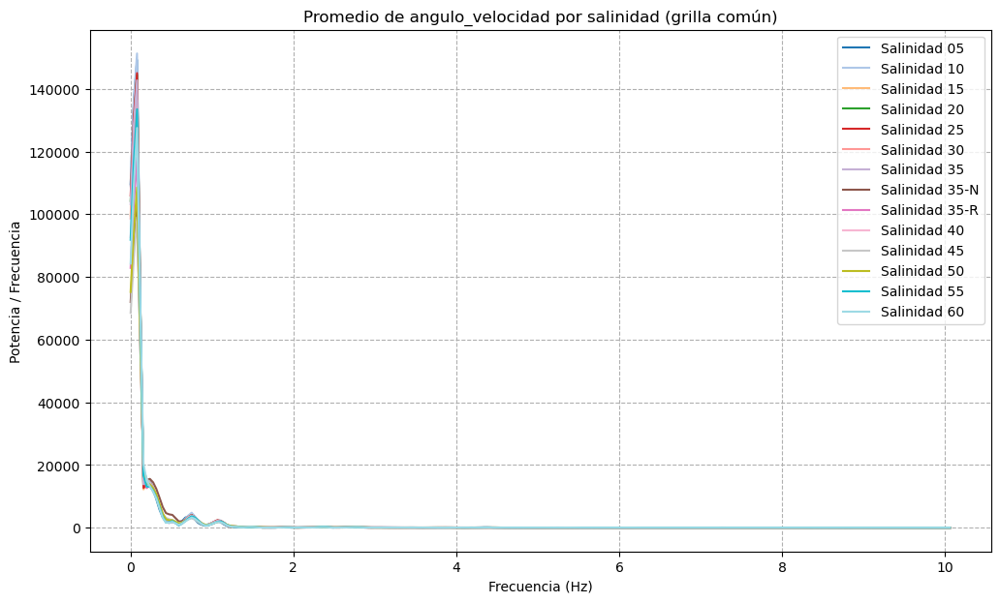


Generando gráficos PSD individuales + media para angulo_velocidad por salinidad (usando grilla global)...


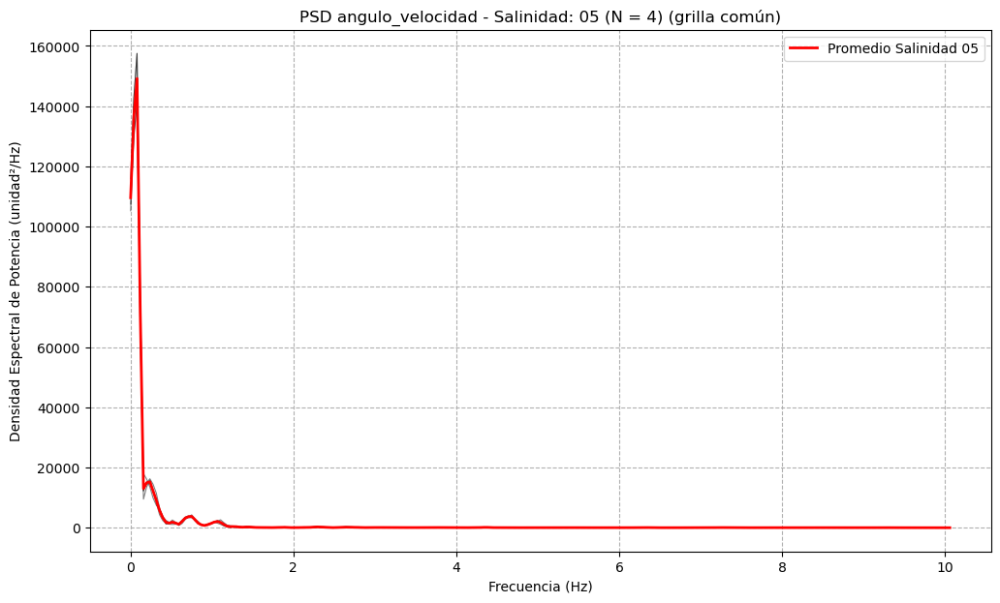

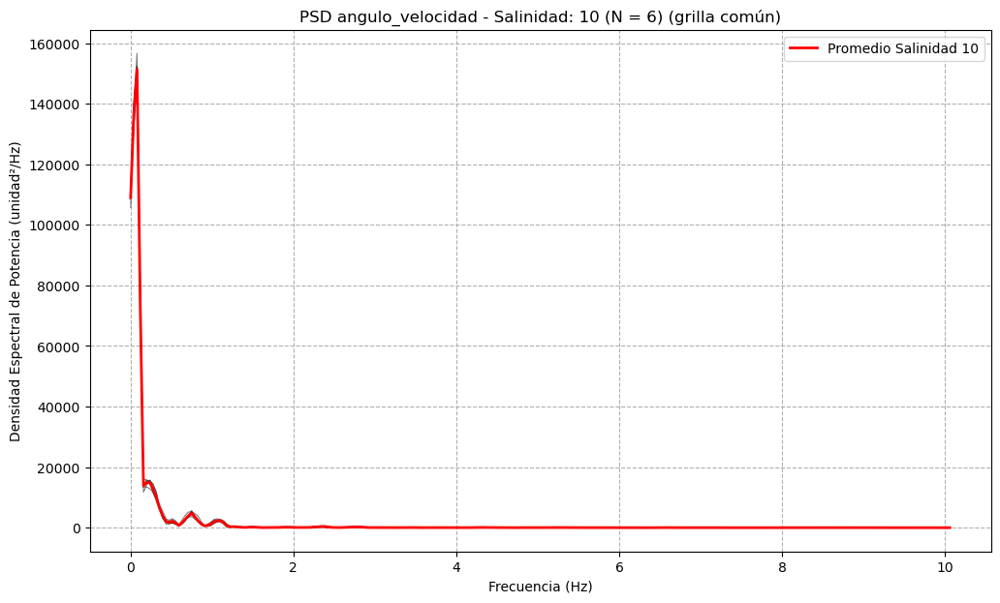

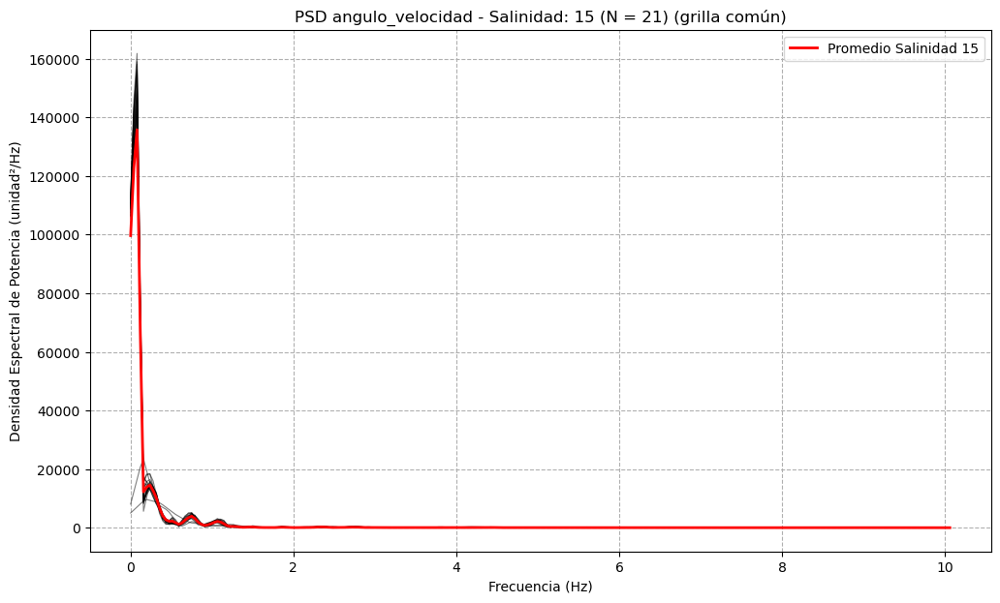

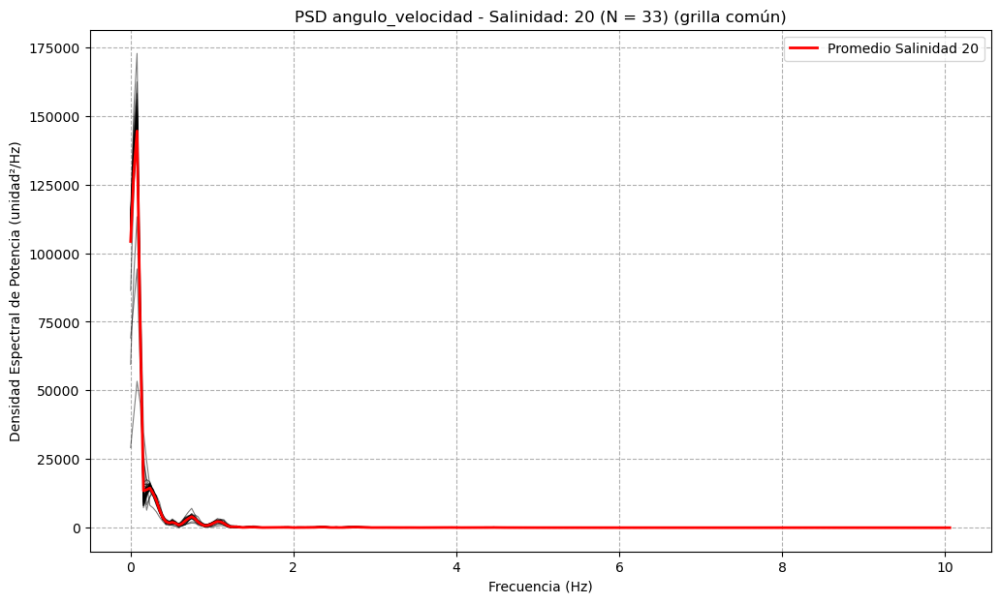

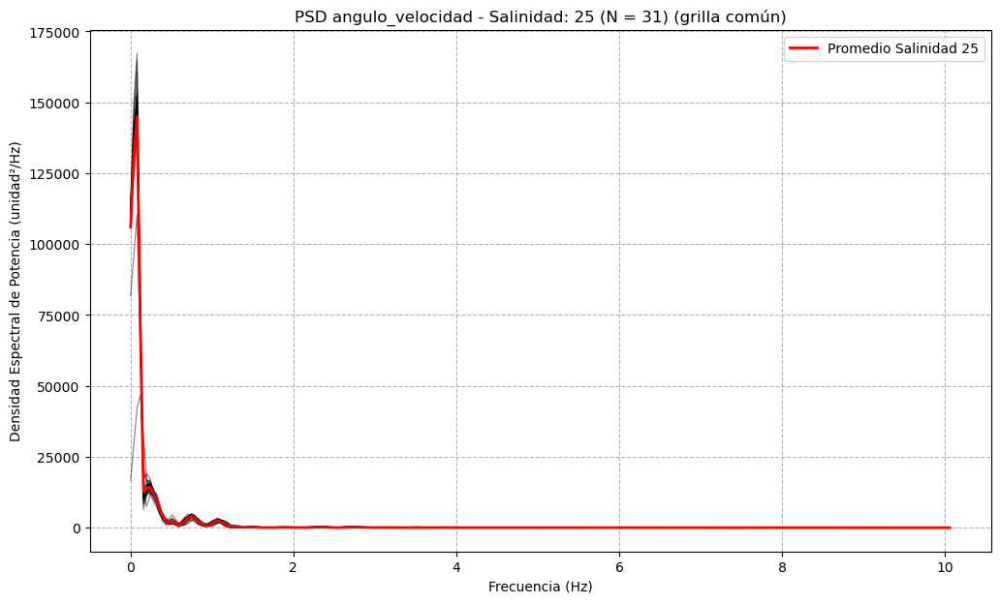

...

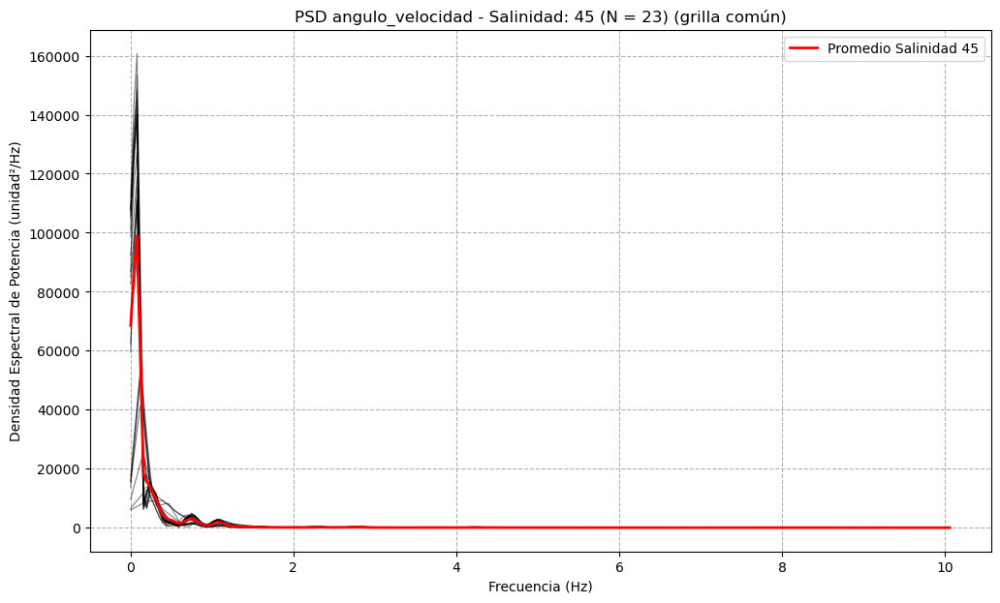

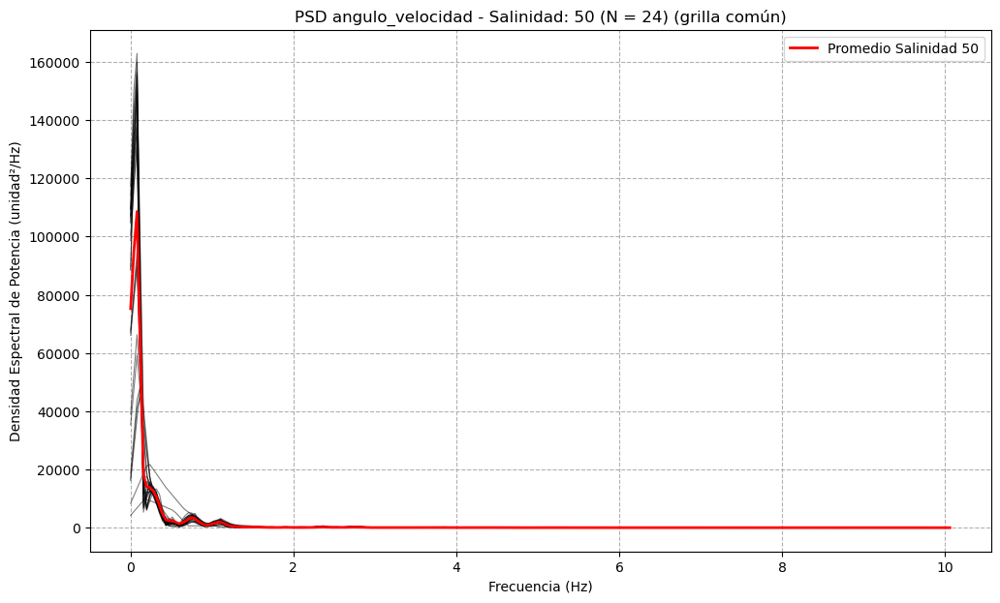

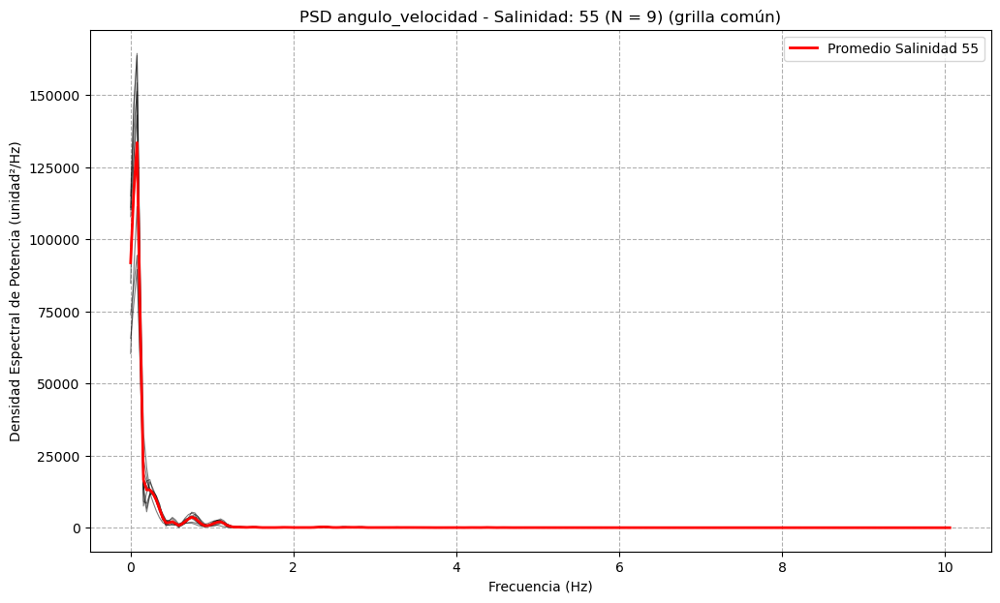

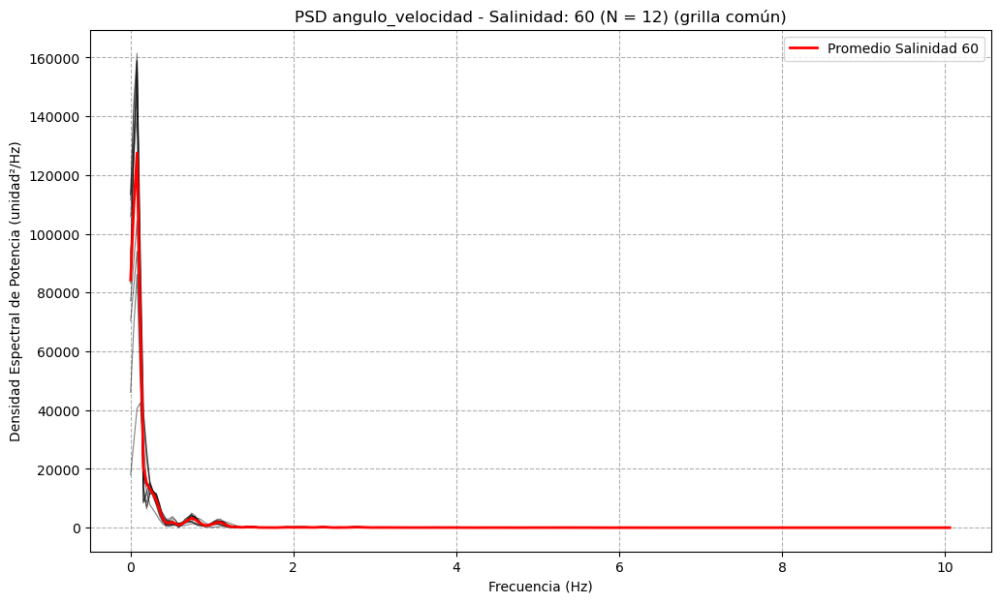

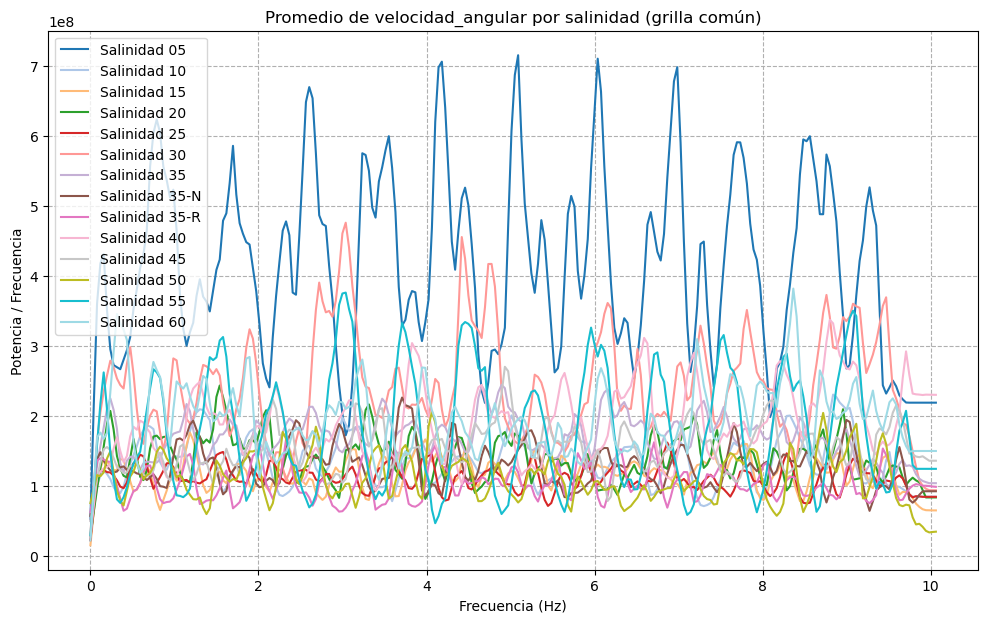


Generando gráficos PSD individuales + media para velocidad_angular por salinidad (usando grilla global)...


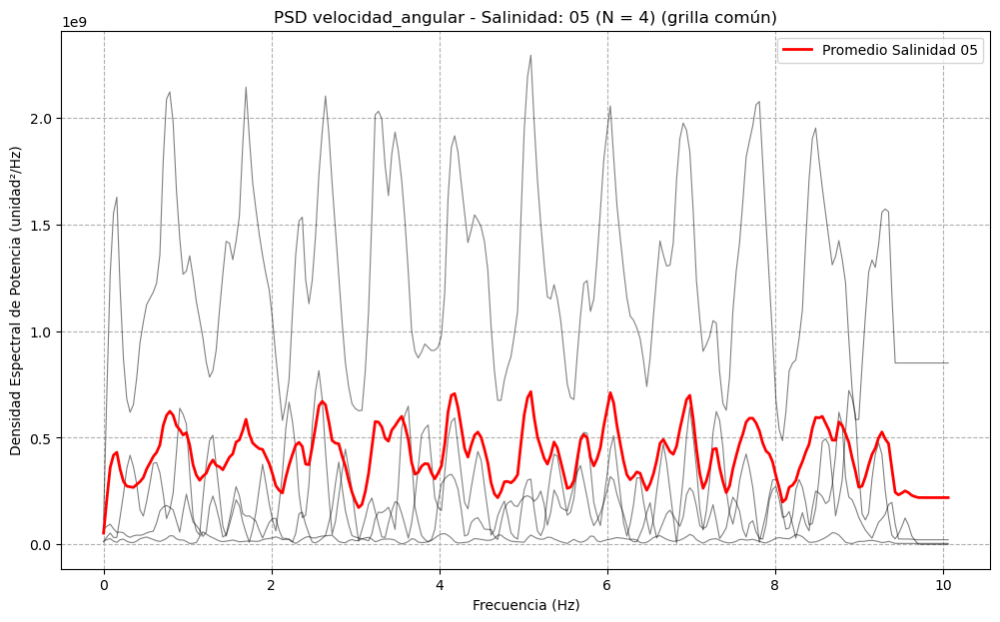

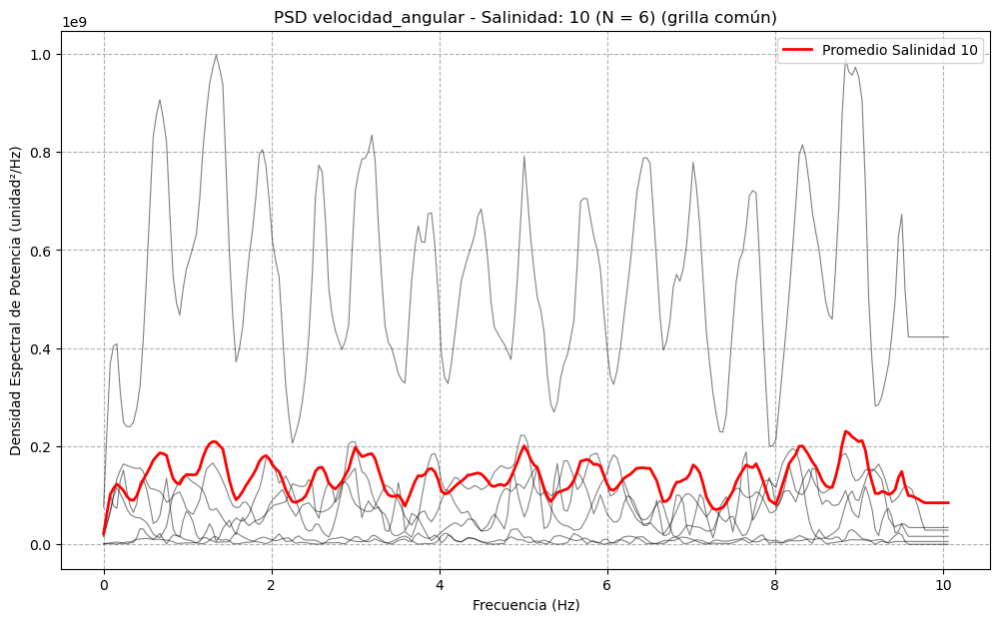

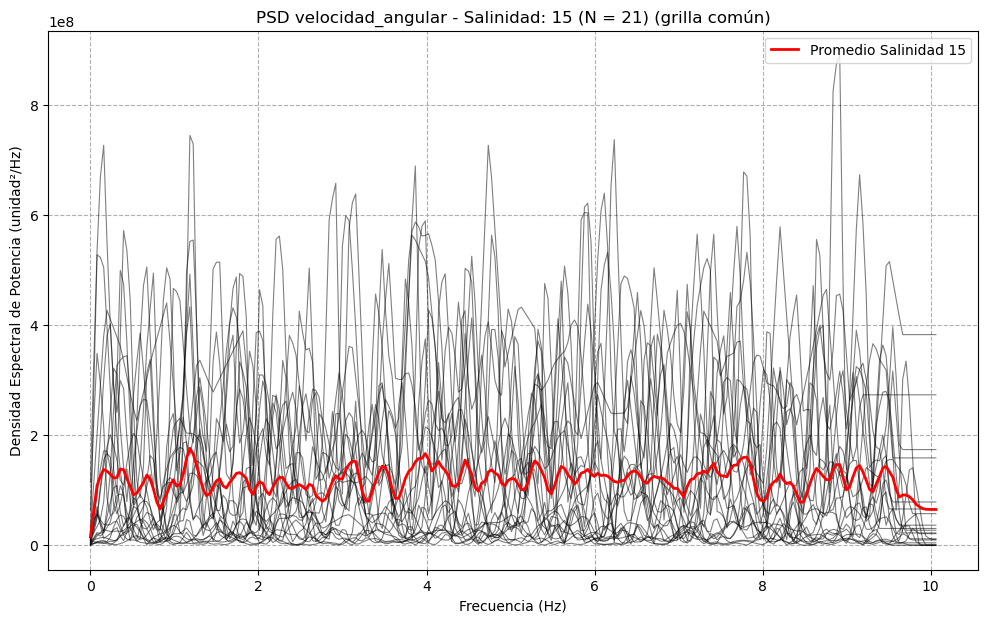

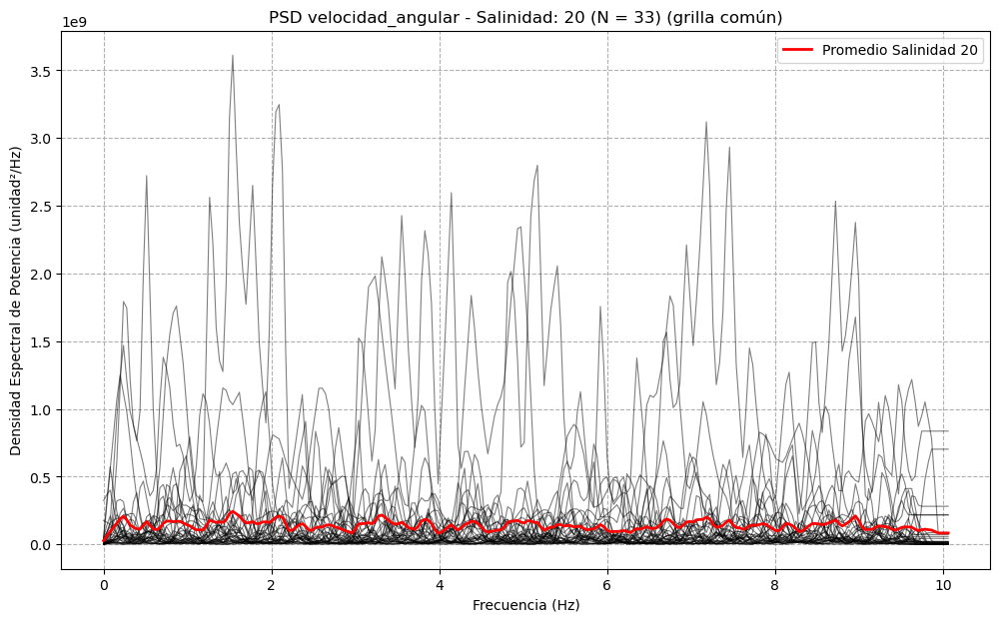

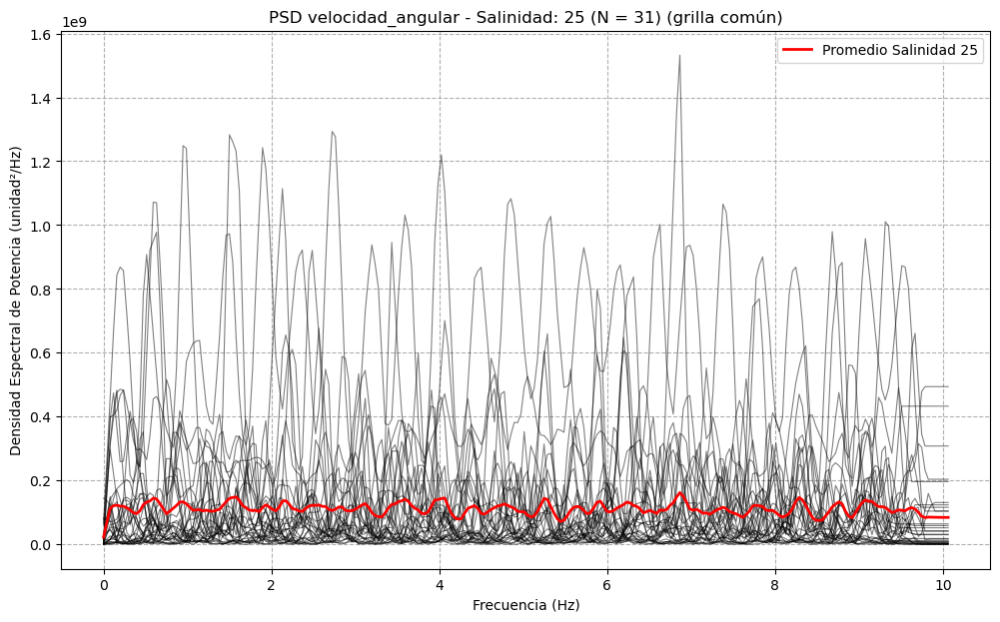

...

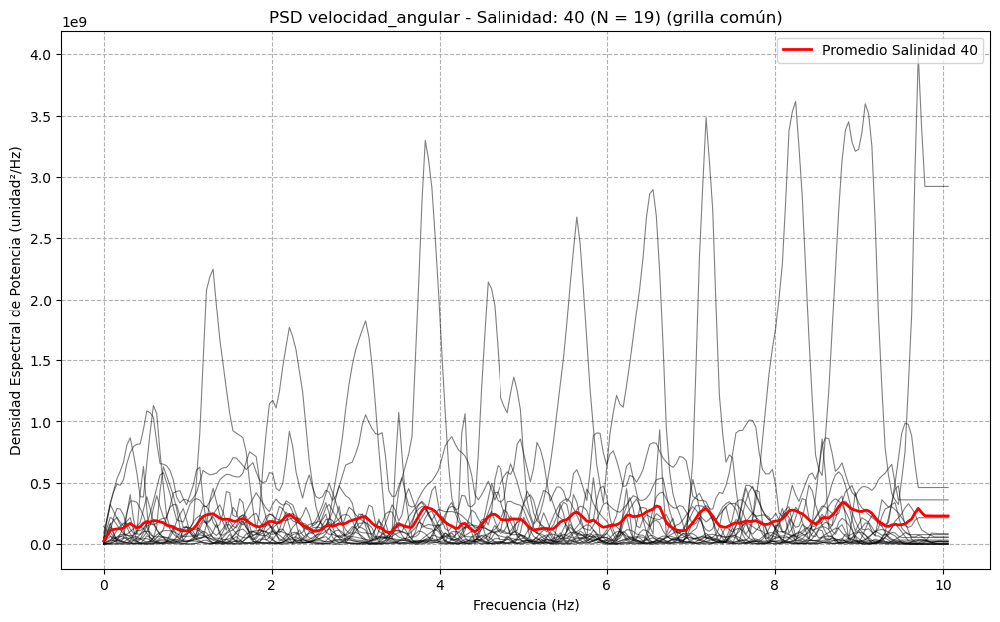

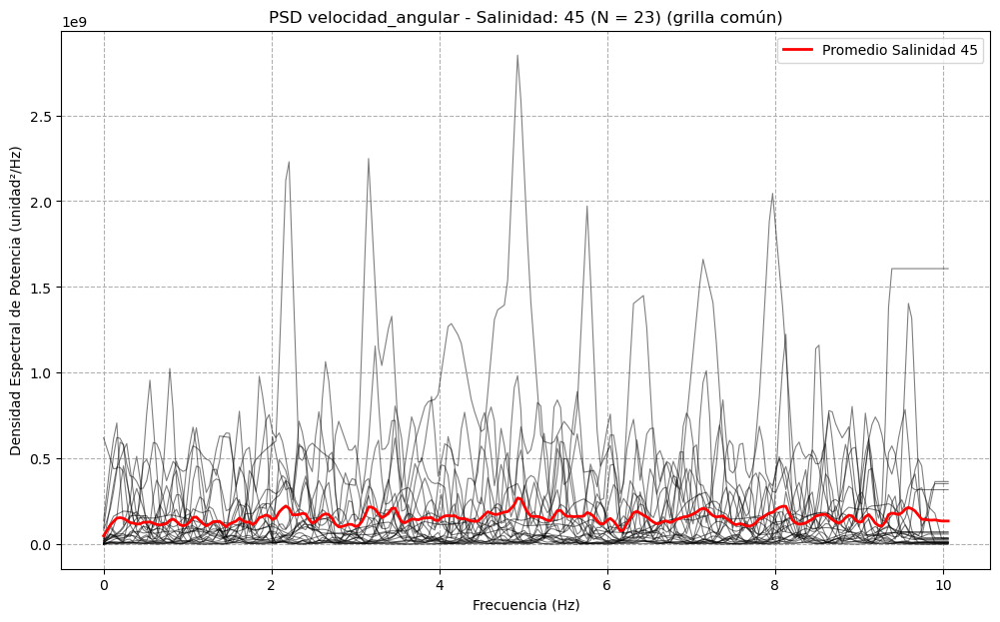

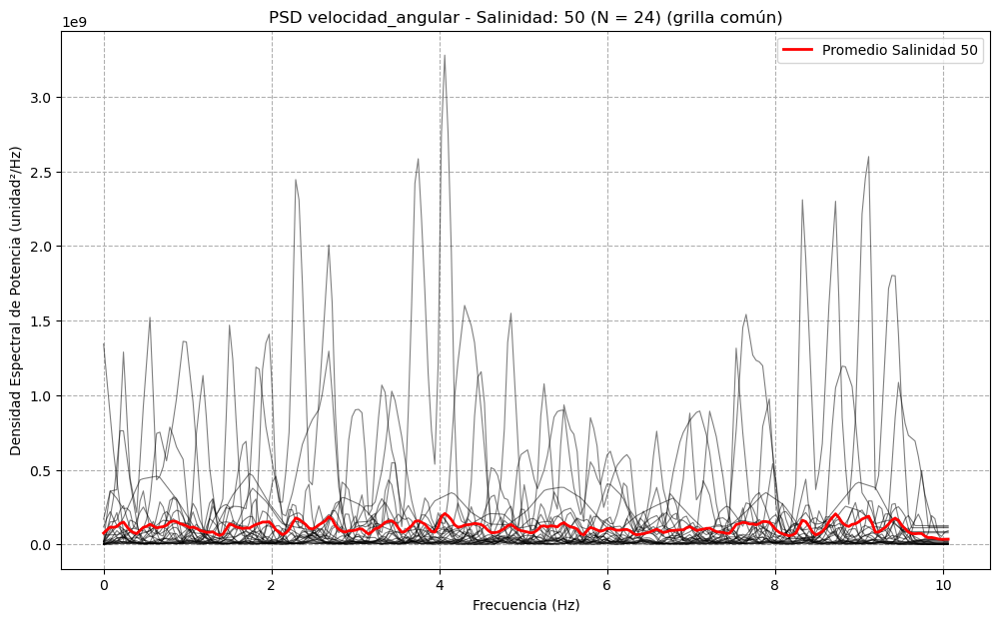

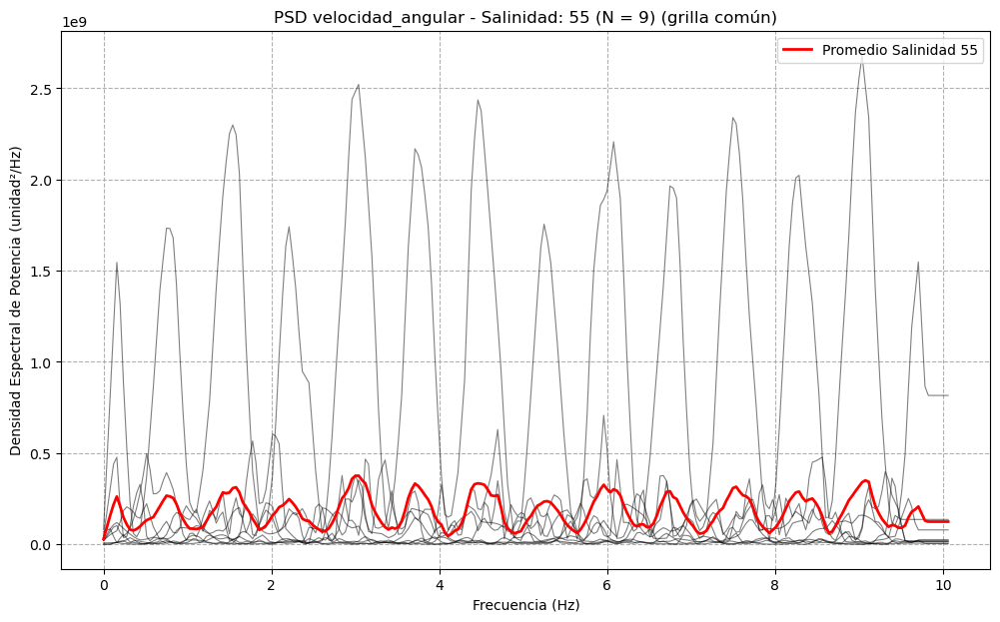

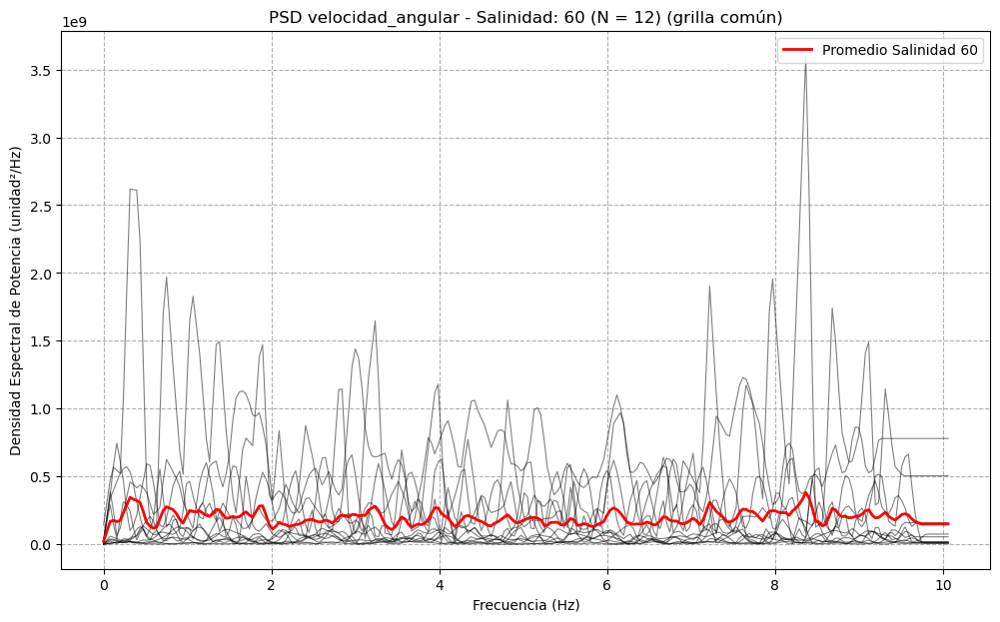

In [ ]:
from scipy.signal import welch

variables = ['v', 'a', 'r', 'angulo_posicion', 'angulo_velocidad', 'velocidad_angular']


lista_psd_originales_todos = []
todas_las_frecuencias_max_global = []

print("Calculando PSD para cada trayectoria y variable...")
for variable_actual in variables:
    lista_psd_variable_actual = []
    for id_video, grupo_video in df.groupby('id'):
        data_serie = grupo_video[variable_actual].dropna()
        tiempo = grupo_video.loc[data_serie.index, 't']

        if len(data_serie) < 20:
            continue
        intervalos_tiempo = np.diff(tiempo)
        if np.any(intervalos_tiempo <= 1e-9):
            continue
        fs_video = 1.0 / np.mean(intervalos_tiempo)
        
        nperseg_val = min(len(data_serie), 256)
        frecuencias_video, psd_video = welch(data_serie, fs=fs_video, nperseg=nperseg_val, scaling='density')
        
        lista_psd_variable_actual.append({
            'id': id_video,
            'salinidad': grupo_video['salinidad'].iloc[0],
            'frecuencias_originales': frecuencias_video,
            'psd_original': psd_video,
            'fs_video': fs_video,
            'variable': variable_actual
        })
        if len(frecuencias_video) > 0:
            todas_las_frecuencias_max_global.append(frecuencias_video[-1])
    lista_psd_originales_todos.extend(lista_psd_variable_actual)


if not lista_psd_originales_todos:
    print("No se pudieron calcular PSDs para ningún video. Revisa los datos de entrada.")
else:
    print(f"PSD calculada para {len(lista_psd_originales_todos)} combinaciones de video/variable.")
    
    df_psd_global = pd.DataFrame(lista_psd_originales_todos)

    # --- Definimos UNA ÚNICA GRILLA DE FRECUENCIAS COMÚN GLOBAL ---
    if not todas_las_frecuencias_max_global:
        print("No hay frecuencias máximas para definir la grilla común. Usando default.")
        f_max_comun_global = 10.0 # Un default si todo falló
    else:
        f_max_comun_global = max(todas_las_frecuencias_max_global)
        

    if f_max_comun_global <= 1e-3: f_max_comun_global = 10.0 
    
    grid_frecuencias_comun_global = np.linspace(1e-3, f_max_comun_global, 256)

    print(f"\nUsando grilla de frecuencias común global hasta {f_max_comun_global:.2f} Hz")

    for variable_actual in variables:
        df_psd_variable_actual = df_psd_global[df_psd_global['variable'] == variable_actual]
        
        if df_psd_variable_actual.empty:
            print(f"No hay datos PSD para la variable {variable_actual}")
            continue

        plt.figure(figsize=(12, 7))
        plt.title(f'Promedio de {variable_actual} por salinidad (grilla común)')
        
        salinidades_unicas_var = sorted(df_psd_variable_actual['salinidad'].unique())
        cmap_var = plt.get_cmap('tab20', len(salinidades_unicas_var) if len(salinidades_unicas_var) > 0 else 1)
        color_dict_var = {sal: cmap_var(i % cmap_var.N) for i, sal in enumerate(salinidades_unicas_var)}

        for salinidad_nivel in salinidades_unicas_var:
            datos_grupo_salinidad = df_psd_variable_actual[df_psd_variable_actual['salinidad'] == salinidad_nivel]
            psds_grupo_interpoladas = []
            for _, fila in datos_grupo_salinidad.iterrows():
                if len(fila['frecuencias_originales']) > 0 and fila['frecuencias_originales'][-1] > 0:
                    psd_interp_grupo = np.interp(grid_frecuencias_comun_global, fila['frecuencias_originales'], fila['psd_original'])
                    psds_grupo_interpoladas.append(psd_interp_grupo)
            
            if psds_grupo_interpoladas:
                psd_media_grupo = np.mean(psds_grupo_interpoladas, axis=0)
                plt.plot(grid_frecuencias_comun_global, psd_media_grupo, 
                           label=f"Salinidad {salinidad_nivel}", # acá está el cambio con log
                           color=color_dict_var.get(salinidad_nivel))
        
        plt.xlabel('Frecuencia (Hz)')
        plt.ylabel('Potencia / Frecuencia')
        plt.legend()
        plt.grid(True, which="both", linestyle='--')
        plt.show()

        print(f"\nGenerando gráficos PSD individuales + media para {variable_actual} por salinidad (usando grilla global)...")
        for salinidad_actual in salinidades_unicas_var:
            df_grupo_salinidad_actual = df_psd_variable_actual[df_psd_variable_actual['salinidad'] == salinidad_actual]
            
            if df_grupo_salinidad_actual.empty:
                continue

            lista_psd_interpoladas_grupo_actual = []
            for _, fila in df_grupo_salinidad_actual.iterrows():
                if len(fila['frecuencias_originales']) > 0 and fila['frecuencias_originales'][-1] > 0:
                    psd_interp = np.interp(
                        grid_frecuencias_comun_global,
                        fila['frecuencias_originales'],
                        fila['psd_original']
                    )
                    lista_psd_interpoladas_grupo_actual.append(psd_interp)
            
            if not lista_psd_interpoladas_grupo_actual:
                continue

            plt.figure(figsize=(12, 7))
            for psd_ind in lista_psd_interpoladas_grupo_actual:
                plt.plot(grid_frecuencias_comun_global, psd_ind, color='black', alpha=0.5, linewidth=0.8)
            
            psd_promedio_grupo_actual = np.mean(np.vstack(lista_psd_interpoladas_grupo_actual), axis=0)
            plt.plot(grid_frecuencias_comun_global, psd_promedio_grupo_actual, color='red', linewidth=2, label=f'Promedio Salinidad {salinidad_actual}')
            
            plt.title(f'PSD {variable_actual} - Salinidad: {salinidad_actual} (N = {len(lista_psd_interpoladas_grupo_actual)}) (grilla común)')
            plt.xlabel('Frecuencia (Hz)')
            plt.ylabel('Densidad Espectral de Potencia (unidad²/Hz)')
            plt.grid(True, which="both", linestyle='--')
            plt.legend(loc='upper right')
            plt.savefig(output_dir / f'psd_ind_y_media_{variable_actual}_salinidad_{salinidad_actual}_globalgrid.png', dpi=300, bbox_inches='tight')
            plt.show()

In [ ]:
print(df.columns)

Index(['id', 't', 'x', 'y', 'vx', 'vy', 'v', 'ax', 'ay', 'a', 'id_ubicacion',
       'especie', 'tratamiento', 'salinidad', 'nombre_archivo',
       'estadio_larval', 'obs', 'video_analizado', 'larva_unica',
       'duracion_video', 'angulo_posicion', 'angulo_velocidad',
       'velocidad_angular', 'x_centrada', 'y_centrada', 'r'],
      dtype='object')
